# Punctuation Restoration for Mental-Health Counselling Text

## 0. Setup

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
ROOT = "/content/punctuation_restoration" if IN_COLAB else os.path.abspath("..")
os.makedirs(ROOT, exist_ok=True); os.chdir(ROOT)
for d in ("src/punct", "scripts", "data/raw", "results/figures", "results/tables", "results/logs", "results/preds", "models"):
    os.makedirs(d, exist_ok=True)
if IN_COLAB:
    subprocess.run("pip -q install transformers==4.46.3 kagglehub", shell=True)
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.is_available(), "| cwd:", os.getcwd())

torch 2.14.1+cu130 | GPU: True | cwd: /content/punctuation_restoration


## 1. Project source code

In [2]:
%%writefile src/punct/__init__.py



Writing src/punct/__init__.py


In [3]:
%%writefile src/punct/data.py
from __future__ import annotations

import json
import random
import re
import unicodedata
from dataclasses import dataclass, field

import pandas as pd

from .labels import CHAR2LABEL, PRIORITY, render


def load_raw(path: str) -> pd.DataFrame:
    return pd.read_csv(path, encoding="utf-8")


_TRANSLATE = {
    " ": " ", "’": "'", "‘": "'", "“": '"', "”": '"',
    "–": " - ", "—": " - ", "…": ". ", "·": "\n", "•": "\n",
    "\r": "\n", "\t": " ",
}
URL_RE = re.compile(r"(https?://\S+|www\.\S+|\S+\.(com|org|net|edu|gov)(/\S*)?)", re.I)
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
BASE64_RE = re.compile(r"(data:image/\S+|[A-Za-z0-9+/=]{40,})")
HTML_RE = re.compile(r"<[^>]+>")
EMOTICON_RE = re.compile(r"(?<!\w)[:;=][-']?[)(DPp/\\|](?!\w)")

GLUED_END_RE = re.compile(r"([a-z0-9)\"'])([.?!]+)([A-Z])")
GLUED_COMMA_RE = re.compile(r"([a-zA-Z])([,;:])([a-zA-Z])")
REPEAT_PUNCT_RE = re.compile(r"([.?!,])[.?!,]+")


def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    for a, b in _TRANSLATE.items():
        text = text.replace(a, b)
    text = HTML_RE.sub(" ", text)
    text = BASE64_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = EMOTICON_RE.sub(" ", text)
    text = GLUED_END_RE.sub(r"\1\2 \3", text)
    text = GLUED_COMMA_RE.sub(r"\1\2 \3", text)

    text = re.sub(r"[?!]*\?[?!]*", "?", text)
    text = REPEAT_PUNCT_RE.sub(r"\1", text)

    lines = [l.strip(" -*#>") for l in text.split("\n")]
    lines = [l for l in lines if l]
    lines = [l if re.search(r"[.?!:,;]['\")\]]*$", l) else l + "." for l in lines]
    text = " ".join(lines)
    text = re.sub(r"\s+", " ", text).strip()
    return text


SPANISH_HINTS = {"que", "de", "el", "la", "los", "las", "por", "una", "es", "mi", "con", "para", "pero", "muy"}


def is_english(text: str) -> bool:
    words = re.findall(r"[a-záéíóúñü]+", text.lower())
    if not words:
        return False
    non_ascii = sum(1 for c in text if ord(c) > 127) / max(1, len(text))
    spanish = sum(w in SPANISH_HINTS for w in words) / len(words)
    return non_ascii < 0.01 and spanish < 0.08


ABBREVIATIONS = {"dr", "mr", "mrs", "ms", "st", "jr", "sr", "vs", "etc", "eg", "ie", "am", "pm", "approx", "dept", "inc"}
WORD_CHARS_RE = re.compile(r"[^a-z0-9']")


def _normalise_word(tok: str) -> list[str]:
    tok = tok.lower().replace("&", " and ").replace("%", " percent ")
    parts = re.split(r"[-/_+]+", tok)
    out = []
    for p in parts:
        for q in p.split():
            q = WORD_CHARS_RE.sub("", q).strip("'")
            if q:
                out.append(q)
    return out


def to_words_labels(text: str) -> tuple[list[str], list[str]]:
    words, labels = [], []
    for raw in text.split():

        m = re.match(r"^([^A-Za-z0-9]*)(.*?)([^A-Za-z0-9]*)$", raw)
        core, trail = m.group(2), m.group(3)

        if not core:
            lab = _label_from_chars(trail + m.group(1))
            if words and PRIORITY[lab] > PRIORITY[labels[-1]]:
                labels[-1] = lab
            continue
        pieces = _normalise_word(core)
        if not pieces:
            continue
        lab = _label_from_chars(trail)

        bare = core.lower().replace(".", "")
        if lab == "PERIOD" and (bare in ABBREVIATIONS or re.fullmatch(r"([a-z]\.){2,}", core.lower() + ".")):
            lab = "O"
        words.extend(pieces)
        labels.extend(["O"] * (len(pieces) - 1) + [lab])
    if labels and labels[-1] in ("O", "COMMA"):
        labels[-1] = "PERIOD"
    return words, labels


def _label_from_chars(chars: str) -> str:
    best = "O"
    for c in chars:
        lab = CHAR2LABEL.get(c, "O")
        if PRIORITY[lab] > PRIORITY[best]:
            best = lab
    return best


@dataclass
class BuildReport:
    raw_rows: int = 0
    missing_response: int = 0
    duplicate_rows: int = 0
    unique_responses: int = 0
    non_english: int = 0
    too_short: int = 0
    duplicates_after_cleaning: int = 0
    final_responses: int = 0
    split_sizes: dict = field(default_factory=dict)


def build_documents(csv_path: str, min_words: int = 5, seed: int = 42,
                    split=(0.8, 0.1, 0.1)) -> tuple[dict, BuildReport]:

    rep = BuildReport()
    df = load_raw(csv_path)
    rep.raw_rows = len(df)
    rep.missing_response = int(df["Response"].isna().sum())
    rep.duplicate_rows = int(df.duplicated().sum())
    resp = df["Response"].dropna()
    resp = resp[resp.str.strip() != ""].drop_duplicates()
    rep.unique_responses = len(resp)

    docs, seen = [], set()
    for idx, raw in resp.items():
        clean = clean_text(raw)
        if not is_english(clean):
            rep.non_english += 1
            continue
        words, labels = to_words_labels(clean)
        if len(words) < min_words:
            rep.too_short += 1
            continue
        key = " ".join(words)
        if key in seen:
            rep.duplicates_after_cleaning += 1
            continue
        seen.add(key)
        docs.append({
            "id": int(idx), "raw": raw, "clean": clean, "words": words, "labels": labels,
            "input_text": " ".join(words), "target_text": render(words, labels),
        })
    rep.final_responses = len(docs)

    rng = random.Random(seed)
    rng.shuffle(docs)
    n = len(docs)
    n_tr, n_va = int(split[0] * n), int(split[1] * n)
    splits = {"train": docs[:n_tr], "val": docs[n_tr:n_tr + n_va], "test": docs[n_tr + n_va:]}
    rep.split_sizes = {k: len(v) for k, v in splits.items()}
    return splits, rep


def make_windows(docs: list[dict], min_len: int = 24, max_len: int = 96, passes: int = 2,
                 seed: int = 0) -> list[dict]:

    rng = random.Random(seed)
    samples = []
    for p in range(passes):
        order = list(range(len(docs)))
        rng.shuffle(order)
        words = [w for i in order for w in docs[i]["words"]]
        labels = [l for i in order for l in docs[i]["labels"]]
        pos = rng.randint(0, max_len // 2) if p else 0
        while pos < len(words):
            L = rng.randint(min_len, max_len)
            samples.append({"words": words[pos:pos + L], "labels": labels[pos:pos + L]})
            pos += L
    return samples


def save_jsonl(items: list[dict], path: str, keys=None) -> None:
    with open(path, "w", encoding="utf-8") as f:
        for it in items:
            if keys:
                it = {k: it[k] for k in keys}
            f.write(json.dumps(it, ensure_ascii=False) + "\n")


def load_jsonl(path: str) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f]


Writing src/punct/data.py


In [4]:
%%writefile src/punct/labels.py
LABELS = ["O", "COMMA", "PERIOD", "QUESTION"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for i, l in enumerate(LABELS)}
PUNCT_LABELS = ["COMMA", "PERIOD", "QUESTION"]

CHAR2LABEL = {
    ",": "COMMA", ";": "COMMA", ":": "COMMA", "-": "COMMA",
    ".": "PERIOD", "!": "PERIOD",
    "?": "QUESTION",
}
LABEL2CHAR = {"O": "", "COMMA": ",", "PERIOD": ".", "QUESTION": "?"}

PRIORITY = {"QUESTION": 3, "PERIOD": 2, "COMMA": 1, "O": 0}


def end_of_input(labels, probs=None):
    labels = list(labels)
    if labels and labels[-1] in ("O", "COMMA"):
        q = probs is not None and probs[-1][LABEL2ID["QUESTION"]] > probs[-1][LABEL2ID["PERIOD"]]
        labels[-1] = "QUESTION" if q else "PERIOD"
    return labels


def render(words, labels, capitalize=False):
    out, start = [], True
    for w, l in zip(words, labels):
        if capitalize:
            if start or w == "i" or w.startswith("i'"):
                w = w[:1].upper() + w[1:]
        out.append(w + LABEL2CHAR[l])
        start = l in ("PERIOD", "QUESTION")
    return " ".join(out)


Writing src/punct/labels.py


In [5]:
%%writefile src/punct/lm_rescore.py
from __future__ import annotations

import heapq
import math
import os

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, get_linear_schedule_with_warmup

from .labels import LABELS, end_of_input, render
from .paths import resolve


def nbest(logp: np.ndarray, k: int = 8, min_prob: float = 0.05):
    beams = [(0.0, [])]
    for row in logp:
        cand = [i for i in np.argsort(-row) if row[i] >= math.log(min_prob)] or [int(row.argmax())]
        nxt = [(s + row[i], seq + [i]) for s, seq in beams for i in cand]
        beams = heapq.nlargest(k, nxt, key=lambda x: x[0])
    return beams


class ExternalLM:
    def __init__(self, name_or_path="distilgpt2", device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        name_or_path = resolve(name_or_path)
        self.tok =AutoTokenizer.from_pretrained(name_or_path)
        self.tok.pad_token = self.tok.eos_token
        self.model = AutoModelForCausalLM.from_pretrained(name_or_path).to(self.device).eval()

    def finetune(self, texts, out_dir, epochs=2, lr=5e-5, block=128, batch_size=8, log_fn=print):
        ids = self.tok("\n".join(texts) + self.tok.eos_token)["input_ids"]
        blocks = [ids[i:i + block] for i in range(0, len(ids) - block, block)]
        dl = DataLoader(_Blocks(blocks), batch_size=batch_size, shuffle=True)
        opt = torch.optim.AdamW(self.model.parameters(), lr=lr, weight_decay=0.01)
        total = epochs * len(dl)
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
        self.model.train()
        step, hist = 0, []
        for ep in range(epochs):
            for x in dl:
                x = x.to(self.device)
                loss = self.model(input_ids=x, labels=x).loss
                loss.backward(); opt.step(); sched.step(); opt.zero_grad()
                step += 1
                hist.append({"step": step, "loss": loss.item()})
                if step % 50 == 0:
                    log_fn(f"  LM step {step}/{total} loss {np.mean([h['loss'] for h in hist[-50:]]):.3f}")
        self.model.eval()
        os.makedirs(out_dir, exist_ok=True)
        self.model.save_pretrained(out_dir); self.tok.save_pretrained(out_dir)
        return hist

    @torch.no_grad()
    def perplexity(self, texts, block=128):
        ids = self.tok("\n".join(texts))["input_ids"]
        nll, n = 0.0, 0
        for i in range(0, len(ids) - 1, block):
            x = torch.tensor([ids[i:i + block + 1]], device=self.device)
            if x.shape[1] < 2:
                break
            logits = self.model(input_ids=x[:, :-1]).logits
            lp = torch.log_softmax(logits.float(), -1).gather(-1, x[:, 1:, None]).squeeze(-1)
            nll -= lp.sum().item(); n += lp.numel()
        return math.exp(nll / n)

    @torch.no_grad()
    def score(self, prefixes, continuations, batch_size=32, prefix_tokens=48):
        all_seqs, all_starts = [], []
        for p, c in zip(prefixes, continuations):
            pid = self.tok(p)["input_ids"][-prefix_tokens:] if p else []
            cid = self.tok((" " if p else "") + c)["input_ids"]
            pid = [self.tok.eos_token_id] + pid
            all_seqs.append(pid + cid); all_starts.append(len(pid))
        order = sorted(range(len(all_seqs)), key=lambda j: len(all_seqs[j]))
        out = [0.0] * len(all_seqs)
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            seqs = [all_seqs[j] for j in idx]
            m = max(map(len, seqs))
            x = torch.full((len(seqs), m), self.tok.eos_token_id, dtype=torch.long)
            att = torch.zeros_like(x)
            for j, s in enumerate(seqs):
                x[j, :len(s)] = torch.tensor(s); att[j, :len(s)] = 1
            x, att = x.to(self.device), att.to(self.device)
            logits = self.model(input_ids=x, attention_mask=att).logits.float()
            lp = torch.log_softmax(logits[:, :-1], -1).gather(-1, x[:, 1:, None]).squeeze(-1)
            for j, s, g in zip(range(len(seqs)), seqs, idx):
                out[g] = lp[j, all_starts[g] - 1:len(s) - 1].sum().item()
        return out


class _Blocks(Dataset):
    def __init__(self, b): self.b = b
    def __len__(self): return len(self.b)
    def __getitem__(self, i): return torch.tensor(self.b[i])


def build_nbest_cache(docs_words, docs_probs, lm: ExternalLM, seg_len=32, k=8, log_fn=None):
    cache = []
    for di, (words, probs) in enumerate(zip(docs_words, docs_probs)):
        logp = np.log(np.clip(probs, 1e-9, 1.0))
        greedy = [LABELS[i] for i in probs.argmax(1)]
        segs = []
        for s in range(0, len(words), seg_len):
            w = words[s:s + seg_len]
            hyps = nbest(logp[s:s + seg_len], k=k)
            prev = render(words[max(0, s - seg_len):s], greedy[max(0, s - seg_len):s])
            segs.append({"start": s, "prefix": prev,
                         "hyps": [{"labels": [LABELS[i] for i in seq], "tag": sc,
                                   "text": render(w, [LABELS[i] for i in seq])} for sc, seq in hyps]})
        cache.append(segs)

    flat = [(seg["prefix"], h["text"]) for segs in cache for seg in segs for h in seg["hyps"]]
    scores = lm.score([p for p, _ in flat], [c for _, c in flat])
    it = iter(scores)
    for segs in cache:
        for seg in segs:
            for h in seg["hyps"]:
                h["lm"] = next(it)
                h["n_punct"] = sum(l != "O" for l in h["labels"])
    return cache


def decode_from_cache(cache, lam=0.3, beta=0.0, end_constraint=True):
    score = lambda h: h["tag"] + lam * h["lm"] + beta * h["n_punct"]
    out = []
    for segs in cache:
        labels = []
        for i, seg in enumerate(segs):
            hyps = seg["hyps"]
            if end_constraint and i == len(segs) - 1:
                hyps = [h for h in hyps if h["labels"][-1] in ("PERIOD", "QUESTION")] or hyps
            labels.extend(max(hyps, key=score)["labels"])
        out.append(end_of_input(labels) if end_constraint else labels)
    return out


Writing src/punct/lm_rescore.py


In [6]:
%%writefile src/punct/metrics.py
from __future__ import annotations

import numpy as np

from .labels import LABEL2ID, LABELS, PUNCT_LABELS


def confusion(refs, hyps):
    cm = np.zeros((len(LABELS), len(LABELS)), dtype=np.int64)
    for r_doc, h_doc in zip(refs, hyps):
        for r, h in zip(r_doc, h_doc):
            cm[LABEL2ID[r], LABEL2ID[h]] += 1
    return cm


def scores_from_confusion(cm):
    out = {}
    tp_all = fp_all = fn_all = 0
    for lab in PUNCT_LABELS:
        i = LABEL2ID[lab]
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        out[lab] = {"precision": p, "recall": r, "f1": f, "support": int(cm[i, :].sum())}
        tp_all += tp; fp_all += fp; fn_all += fn

    p = tp_all / (tp_all + fp_all) if tp_all + fp_all else 0.0
    r = tp_all / (tp_all + fn_all) if tp_all + fn_all else 0.0
    out["micro"] = {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0,
                    "support": int(sum(out[l]["support"] for l in PUNCT_LABELS))}
    out["macro"] = {k: float(np.mean([out[l][k] for l in PUNCT_LABELS]))
                    for k in ("precision", "recall", "f1")}
    o = LABEL2ID["O"]
    punct = [LABEL2ID[l] for l in PUNCT_LABELS]
    subs = sum(cm[i, j] for i in punct for j in punct if i != j)
    dels = sum(cm[i, o] for i in punct)
    ins = sum(cm[o, j] for j in punct)
    ref = sum(cm[i, :].sum() for i in punct)
    out["SER"] = float((subs + dels + ins) / ref) if ref else 0.0
    out["accuracy_all_words"] = float(np.trace(cm) / cm.sum())
    return out


def evaluate(refs, hyps):
    cm = confusion(refs, hyps)
    return scores_from_confusion(cm), cm


def flat_row(name, s):
    row = {"model": name}
    for lab in PUNCT_LABELS:
        row[f"{lab}_P"] = s[lab]["precision"]
        row[f"{lab}_R"] = s[lab]["recall"]
        row[f"{lab}_F1"] = s[lab]["f1"]
    row["micro_P"] = s["micro"]["precision"]
    row["micro_R"] = s["micro"]["recall"]
    row["micro_F1"] = s["micro"]["f1"]
    row["macro_F1"] = s["macro"]["f1"]
    row["SER"] = s["SER"]
    return row


Writing src/punct/metrics.py


In [7]:
%%writefile src/punct/paths.py
import os

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), "..", ".."))


def resolve(name_or_path: str) -> str:
    if os.path.isdir(name_or_path):
        return name_or_path
    local = os.path.join(ROOT, "models", "hf", name_or_path.replace("/", "__"))
    return local if os.path.exists(os.path.join(local, "config.json")) else name_or_path


Writing src/punct/paths.py


In [8]:
%%writefile src/punct/tagger.py
from __future__ import annotations

import math
import os
import time

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import (AutoModelForTokenClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

from .labels import CHAR2LABEL, ID2LABEL, LABEL2ID, LABELS, end_of_input
from .paths import resolve


def fold_label(name: str) -> str:
    n = str(name).strip()
    up = n.upper()
    if up in LABEL2ID:
        return up
    if up in ("0", "O", "LABEL_0", ""):
        return "O"
    for c in n:
        if c in CHAR2LABEL:
            return CHAR2LABEL[c]
    return "O"


class Tagger:
    def __init__(self, name_or_path: str, device: str | None = None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        name_or_path = resolve(name_or_path)
        self.tokenizer = AutoTokenizer.from_pretrained(name_or_path, add_prefix_space=True) \
            if "roberta" in name_or_path.lower() and "xlm" not in name_or_path.lower() \
            else AutoTokenizer.from_pretrained(name_or_path)
        cfg_probe = AutoModelForTokenClassification.from_pretrained
        try:
            self.model = cfg_probe(name_or_path)
            native = {int(i): l for i, l in self.model.config.id2label.items()}

            if all(l.startswith("LABEL_") for l in native.values()):
                raise ValueError("no punctuation head")
        except Exception:
            self.model = cfg_probe(name_or_path, num_labels=len(LABELS),
                                   id2label=ID2LABEL, label2id=LABEL2ID,
                                   ignore_mismatched_sizes=True)
            native = dict(ID2LABEL)
        self.native_id2label = native

        self.fold = np.array([LABEL2ID[fold_label(native[j])] for j in range(len(native))])

        self.target_id = {}
        for ours in LABELS:
            exact = [j for j, n in native.items() if fold_label(n) == ours]
            pref = {"O": ("0", "O"), "COMMA": (",", "COMMA"), "PERIOD": (".", "PERIOD"),
                    "QUESTION": ("?", "QUESTION")}[ours]
            best = [j for j in exact if native[j].strip().upper() in pref]
            self.target_id[ours] = (best or exact)[0]
        self.model.to(self.device)

    def encode(self, words, labels=None, max_length=256):
        enc = self.tokenizer(words, is_split_into_words=True, truncation=True,
                             max_length=max_length)
        word_ids = enc.word_ids()
        if labels is not None:
            lab, prev = [], None
            for wid in word_ids:
                if wid is None or wid == prev:
                    lab.append(-100)
                else:
                    lab.append(self.target_id[labels[wid]])
                prev = wid
            enc["labels"] = lab
        return enc, word_ids

    def train(self, samples, out_dir, epochs=3, lr=5e-5, batch_size=16, max_length=256,
              warmup=0.1, weight_decay=0.01, log_every=50, seed=42, log_fn=print):
        torch.manual_seed(seed)
        ds = _EncodedDataset([self.encode(s["words"], s["labels"], max_length)[0] for s in samples])
        dl = DataLoader(ds, batch_size=batch_size, shuffle=True, collate_fn=self._collate)
        opt = torch.optim.AdamW(self.model.parameters(), lr=lr, weight_decay=weight_decay)
        total = epochs * len(dl)
        sched = get_linear_schedule_with_warmup(opt, int(warmup * total), total)
        history, step, t0 = [], 0, time.time()
        self.model.train()
        for ep in range(epochs):
            run = 0.0
            for b in dl:
                b = {k: v.to(self.device) for k, v in b.items()}
                loss = self.model(**b).loss
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                opt.step(); sched.step(); opt.zero_grad()
                step += 1
                run += loss.item()
                history.append({"step": step, "epoch": ep + step / len(dl) - ep, "loss": loss.item()})
                if step % log_every == 0:
                    log_fn(f"  step {step}/{total}  loss {run / log_every:.4f}  "
                           f"{(time.time() - t0) / step:.2f}s/step")
                    run = 0.0
        self.model.eval()
        os.makedirs(out_dir, exist_ok=True)
        self.model.save_pretrained(out_dir)
        self.tokenizer.save_pretrained(out_dir)
        return history

    def _collate(self, batch):
        m = max(len(x["input_ids"]) for x in batch)
        pad = self.tokenizer.pad_token_id
        out = {"input_ids": [], "attention_mask": [], "labels": []}
        for x in batch:
            n = len(x["input_ids"])
            out["input_ids"].append(x["input_ids"] + [pad] * (m - n))
            out["attention_mask"].append([1] * n + [0] * (m - n))
            if "labels" in x:
                out["labels"].append(x["labels"] + [-100] * (m - n))
        if not out["labels"]:
            del out["labels"]
        return {k: torch.tensor(v) for k, v in out.items()}

    @torch.no_grad()
    def predict_proba(self, docs_words, window=100, stride=50, batch_size=32, max_length=256):
        self.model.eval()
        jobs = []
        for di, words in enumerate(docs_words):
            starts = list(range(0, max(1, len(words) - window + stride), stride)) or [0]
            for s in starts:
                jobs.append((di, s, words[s:s + window]))
        probs = [np.zeros((len(w), len(LABELS)), dtype=np.float32) for w in docs_words]
        best_margin = [np.full(len(w), -1.0) for w in docs_words]
        for i in range(0, len(jobs), batch_size):
            chunk = jobs[i:i + batch_size]
            encs = [self.encode(w, None, max_length) for _, _, w in chunk]
            batch = self._collate([dict(e) for e, _ in encs])
            batch = {k: v.to(self.device) for k, v in batch.items() if k != "token_type_ids"}
            logits = self.model(**batch).logits.float()
            p_native = torch.softmax(logits, -1).cpu().numpy()
            for (di, s, w), (enc, wids), p in zip(chunk, encs, p_native):
                folded = np.zeros((p.shape[0], len(LABELS)), dtype=np.float32)
                np.add.at(folded.T, self.fold, p.T)
                prev = None
                for t, wid in enumerate(wids):
                    if wid is None or wid == prev:
                        prev = wid
                        continue
                    prev = wid
                    g = s + wid

                    left = wid if s > 0 else 10 ** 6
                    right = len(w) - 1 - wid if s + len(w) < len(docs_words[di]) else 10 ** 6
                    margin = min(left, right)
                    if margin > best_margin[di][g]:
                        best_margin[di][g] = margin
                        probs[di][g] = folded[t]

        for p in probs:
            p[p.sum(1) == 0] = np.eye(len(LABELS))[0]
        return probs

    def predict(self, docs_words, end_constraint=True, **kw):
        out = []
        for p in self.predict_proba(docs_words, **kw):
            lab = [LABELS[i] for i in p.argmax(1)]
            out.append(end_of_input(lab, p) if end_constraint else lab)
        return out


class _EncodedDataset(Dataset):
    def __init__(self, encs):
        self.encs = [{k: list(v) for k, v in e.items() if k in ("input_ids", "labels")} for e in encs]

    def __len__(self):
        return len(self.encs)

    def __getitem__(self, i):
        return self.encs[i]


Writing src/punct/tagger.py


In [9]:
%%writefile scripts/01_build_dataset.py
import json
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import pandas as pd

from punct.data import build_documents, make_windows, save_jsonl

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
RAW = os.path.join(ROOT, "data", "raw", "train.csv")
OUT = os.path.join(ROOT, "data", "processed")
TAB = os.path.join(ROOT, "results", "tables")
os.makedirs(OUT, exist_ok=True); os.makedirs(TAB, exist_ok=True)

splits, rep = build_documents(RAW, min_words=5, seed=42)
keys = ["id", "raw", "clean", "words", "labels", "input_text", "target_text"]
for name, docs in splits.items():
    save_jsonl(docs, os.path.join(OUT, f"{name}.jsonl"), keys)

windows = make_windows(splits["train"], min_len=24, max_len=96, passes=2, seed=0)
save_jsonl(windows, os.path.join(OUT, "train_windows.jsonl"))

rows = []
for name, docs in splits.items():
    for d in docs:
        rows.append({"split": name, "id": d["id"], "n_words": len(d["words"]),
                     "input_text": d["input_text"], "target_text": d["target_text"],
                     "labels": " ".join(d["labels"])})
pd.DataFrame(rows).to_csv(os.path.join(OUT, "synthetic_dataset.csv"), index=False)

report = rep.__dict__ | {"train_windows": len(windows)}
with open(os.path.join(TAB, "dataset_report.json"), "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))


Writing scripts/01_build_dataset.py


In [10]:
%%writefile scripts/02_eda.py
import collections
import json
import os
import re
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from punct.data import load_jsonl, load_raw
from punct.labels import LABELS, PUNCT_LABELS

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
FIG = os.path.join(ROOT, "results", "figures"); os.makedirs(FIG, exist_ok=True)
TAB = os.path.join(ROOT, "results", "tables")
COL = {"O": "#9aa5b1", "COMMA": "#2a6fdb", "PERIOD": "#1b998b", "QUESTION": "#e4572e"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

train = load_jsonl(os.path.join(ROOT, "data", "processed", "train.jsonl"))
splits = {s: load_jsonl(os.path.join(ROOT, "data", "processed", f"{s}.jsonl")) for s in ("train", "val", "test")}
raw = load_raw(os.path.join(ROOT, "data", "raw", "train.csv"))
summary = {}

summary["raw_columns"] = list(raw.columns)
summary["raw_rows"] = len(raw)
summary["raw_missing"] = raw.isna().sum().to_dict()
summary["contexts_unique"] = int(raw.Context.nunique())
summary["responses_unique"] = int(raw.Response.nunique())
summary["responses_per_context"] = raw.groupby("Context").Response.nunique().describe().round(2).to_dict()

cnt = {s: collections.Counter(l for d in docs for l in d["labels"]) for s, docs in splits.items()}
summary["label_counts"] = {s: dict(c) for s, c in cnt.items()}
summary["label_share_train"] = {l: cnt["train"][l] / sum(cnt["train"].values()) for l in LABELS}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
c = cnt["train"]
ax[0].bar(LABELS, [c[l] for l in LABELS], color=[COL[l] for l in LABELS])
for i, l in enumerate(LABELS):
    ax[0].text(i, c[l], f"{c[l]:,}\n({100 * c[l] / sum(c.values()):.1f}%)", ha="center", va="bottom", fontsize=8)
ax[0].set_title("Label distribution (train, all words)"); ax[0].set_ylabel("words")
ax[0].set_ylim(0, c["O"] * 1.18)
ax[1].bar(PUNCT_LABELS, [c[l] for l in PUNCT_LABELS], color=[COL[l] for l in PUNCT_LABELS])
for i, l in enumerate(PUNCT_LABELS):
    ax[1].text(i, c[l], f"{c[l]:,}", ha="center", va="bottom", fontsize=8)
ax[1].set_title("Punctuation classes only (O removed)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_label_distribution.png")); plt.close()

share = pd.DataFrame({s: {l: cnt[s][l] / sum(cnt[s].values()) * 100 for l in PUNCT_LABELS} for s in splits})
summary["punct_share_per_split_pct"] = share.round(2).to_dict()

n_words = np.array([len(d["words"]) for d in train])
sent_lens = []
for d in train:
    k = 0
    for l in d["labels"]:
        k += 1
        if l in ("PERIOD", "QUESTION"):
            sent_lens.append(k); k = 0
sent_lens = np.array(sent_lens)
comma_per_sent = []
for d in train:
    k = 0
    for l in d["labels"]:
        if l == "COMMA": k += 1
        if l in ("PERIOD", "QUESTION"):
            comma_per_sent.append(k); k = 0
summary["words_per_response"] = pd.Series(n_words).describe().round(1).to_dict()
summary["words_per_sentence"] = pd.Series(sent_lens).describe().round(1).to_dict()
summary["commas_per_sentence_mean"] = float(np.mean(comma_per_sent))
summary["vocab_size_train"] = len({w for d in train for w in d["words"]})

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(n_words, bins=50, color="#2a6fdb"); ax[0].set_title("Words per response")
ax[0].axvline(np.median(n_words), color="k", ls="--", lw=1); ax[0].text(np.median(n_words), ax[0].get_ylim()[1] * .9, f" median {np.median(n_words):.0f}")
ax[1].hist(np.clip(sent_lens, 0, 80), bins=40, color="#1b998b"); ax[1].set_title("Words per sentence (clipped at 80)")
ax[1].axvline(np.median(sent_lens), color="k", ls="--", lw=1); ax[1].text(np.median(sent_lens), ax[1].get_ylim()[1] * .9, f" median {np.median(sent_lens):.0f}")
vals, freqs = np.unique(np.clip(comma_per_sent, 0, 8), return_counts=True)
ax[2].bar(vals, freqs, color="#2a6fdb"); ax[2].set_title("Commas per sentence (8 = 8+)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_lengths.png")); plt.close()

before = {l: collections.Counter() for l in PUNCT_LABELS}
after = {l: collections.Counter() for l in PUNCT_LABELS}
qfirst = collections.Counter()
for d in train:
    w, lab = d["words"], d["labels"]
    start = 0
    for i, l in enumerate(lab):
        if l in before:
            before[l][w[i]] += 1
            if i + 1 < len(w):
                after[l][w[i + 1]] += 1
        if l in ("PERIOD", "QUESTION"):
            if l == "QUESTION":
                qfirst[w[start]] += 1
            start = i + 1
summary["top_word_before"] = {l: before[l].most_common(10) for l in before}
summary["top_word_after"] = {l: after[l].most_common(10) for l in after}
summary["question_first_word"] = qfirst.most_common(12)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (title, counter, col) in zip(ax, [
        ("Word AFTER a comma", after["COMMA"], COL["COMMA"]),
        ("Word BEFORE a period", before["PERIOD"], COL["PERIOD"]),
        ("FIRST word of a question", qfirst, COL["QUESTION"])]):
    items = counter.most_common(12)[::-1]
    a.barh([k for k, _ in items], [v for _, v in items], color=col); a.set_title(title)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_lexical_cues.png")); plt.close()

pos = {l: [] for l in PUNCT_LABELS}
for d in train:
    n = len(d["labels"])
    for i, l in enumerate(d["labels"][:-1]):
        if l in pos:
            pos[l].append(i / max(1, n - 1))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for l in PUNCT_LABELS:
    ax.hist(pos[l], bins=20, density=True, histtype="step", lw=2, color=COL[l], label=l)
ax.set_xlabel("relative position in response (0 = start, 1 = end)"); ax.set_ylabel("density")
ax.set_title("Where punctuation occurs inside a response"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_position.png")); plt.close()

raw_resp = raw.Response.dropna().drop_duplicates()
issues = {
    "missing_space_after_sentence_end": int(raw_resp.str.count(r"[a-z][.?!][A-Z]").sum()),
    "non_breaking_spaces": int(raw_resp.str.count(" ").sum()),
    "urls": int(raw_resp.str.count(r"https?://|www\.").sum()),
    "curly_quotes_apostrophes": int(raw_resp.str.count("[‘’“”]").sum()),
    "responses_with_newlines": int(raw_resp.str.contains("\n").sum()),
    "spanish_responses": summary.get("non_english", None),
}
rep = json.load(open(os.path.join(TAB, "dataset_report.json")))
issues["spanish_responses"] = rep["non_english"]
summary["raw_issues"] = issues
fig, ax = plt.subplots(figsize=(7, 3))
k = list(issues); v = [issues[x] for x in k]
ax.barh(k[::-1], v[::-1], color="#e4572e")
for i, x in enumerate(v[::-1]): ax.text(x, i, f" {x:,}", va="center", fontsize=8)
ax.set_title("Problems found in the raw Response column"); ax.set_xscale("log")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_raw_issues.png")); plt.close()

funnel = [("raw rows", rep["raw_rows"]), ("non-missing", rep["raw_rows"] - rep["missing_response"]),
          ("unique responses", rep["unique_responses"]),
          ("English", rep["unique_responses"] - rep["non_english"]),
          ("unique after cleaning", rep["final_responses"])]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh([f[0] for f in funnel][::-1], [f[1] for f in funnel][::-1], color="#2a6fdb")
for i, (_, x) in enumerate(funnel[::-1]): ax.text(x, i, f" {x:,}", va="center", fontsize=8)
ax.set_title("Cleaning funnel (rows kept after each step)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda_cleaning_funnel.png")); plt.close()

with open(os.path.join(TAB, "eda_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps({k: summary[k] for k in ("label_share_train", "words_per_response", "words_per_sentence",
                                          "question_first_word", "raw_issues", "vocab_size_train")}, indent=1, default=str))


Writing scripts/02_eda.py


In [11]:
%%writefile scripts/03_run_tagger.py
import argparse
import json
import os
import pickle
import sys
import time

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import torch

from punct.data import load_jsonl
from punct.labels import LABELS
from punct.metrics import evaluate
from punct.tagger import Tagger

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
P = lambda *a: os.path.join(ROOT, *a)

ap = argparse.ArgumentParser()
ap.add_argument("--tag", required=True)
ap.add_argument("--model", required=True)
ap.add_argument("--train", action="store_true")
ap.add_argument("--epochs", type=int, default=3)
ap.add_argument("--lr", type=float, default=5e-5)
ap.add_argument("--batch_size", type=int, default=16)
ap.add_argument("--limit_train", type=int, default=0, help="debug: use only N windows")
ap.add_argument("--threads", type=int, default=0)
args = ap.parse_args()
if args.threads:
    torch.set_num_threads(args.threads)
os.makedirs(P("results", "preds"), exist_ok=True); os.makedirs(P("results", "logs"), exist_ok=True)

log_path = P("results", "logs", f"{args.tag}.log")


def log(msg):
    print(msg, flush=True)
    with open(log_path, "a", encoding="utf-8") as f:
        f.write(msg + "\n")


log(f"== {args.tag}: {args.model}  train={args.train}  device={'cuda' if torch.cuda.is_available() else 'cpu'}")
tagger = Tagger(args.model)
log(f"native labels: {tagger.native_id2label}  ->  fold {tagger.fold.tolist()}")
n_params = sum(p.numel() for p in tagger.model.parameters())
log(f"parameters: {n_params / 1e6:.1f} M")

val = load_jsonl(P("data", "processed", "val.jsonl"))
test = load_jsonl(P("data", "processed", "test.jsonl"))

meta = {"tag": args.tag, "model": args.model, "params_M": n_params / 1e6, "trained": args.train}
if args.train:
    windows = load_jsonl(P("data", "processed", "train_windows.jsonl"))
    if args.limit_train:
        windows = windows[:args.limit_train]
    t0 = time.time()
    hist = tagger.train(windows, P("models", args.tag), epochs=args.epochs, lr=args.lr,
                        batch_size=args.batch_size, log_fn=log)
    meta.update(train_seconds=time.time() - t0, epochs=args.epochs, lr=args.lr,
                batch_size=args.batch_size, train_windows=len(windows))
    json.dump(hist, open(P("results", "logs", f"{args.tag}_loss.json"), "w"))

out = {"meta": meta}
for name, docs in (("val", val), ("test", test)):
    t0 = time.time()
    probs = tagger.predict_proba([d["words"] for d in docs])
    out[name] = probs
    s, _ = evaluate([d["labels"] for d in docs], [[LABELS[i] for i in p.argmax(1)] for p in probs])
    meta[f"{name}_infer_seconds"] = time.time() - t0
    log(f"{name}: micro-F1 {s['micro']['f1']:.4f}  COMMA {s['COMMA']['f1']:.3f}  PERIOD {s['PERIOD']['f1']:.3f}"
        f"  QUESTION {s['QUESTION']['f1']:.3f}  SER {s['SER']:.3f}  ({time.time() - t0:.0f}s)")
with open(P("results", "preds", f"{args.tag}.pkl"), "wb") as f:
    pickle.dump(out, f)
log("done")


Writing scripts/03_run_tagger.py


In [12]:
%%writefile scripts/04_external_lm.py
import argparse
import itertools
import json
import os
import pickle
import sys
import time

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import numpy as np

from punct.data import load_jsonl
from punct.labels import LABELS, end_of_input
from punct.lm_rescore import ExternalLM, build_nbest_cache, decode_from_cache
from punct.metrics import evaluate

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
P = lambda *a: os.path.join(ROOT, *a)

ap = argparse.ArgumentParser()
ap.add_argument("--tagger", default="distilbert_finetuned")
ap.add_argument("--lm_epochs", type=int, default=2)
ap.add_argument("--k", type=int, default=8)
ap.add_argument("--seg_len", type=int, default=32)
args = ap.parse_args()

log_path = P("results", "logs", f"external_lm_{args.tagger}.log")


def log(m):
    print(m, flush=True)
    open(log_path, "a", encoding="utf-8").write(m + "\n")


train = load_jsonl(P("data", "processed", "train.jsonl"))
val = load_jsonl(P("data", "processed", "val.jsonl"))
test = load_jsonl(P("data", "processed", "test.jsonl"))

dom_dir = P("models", "distilgpt2_domain")
lm_info = {}
if not os.path.exists(os.path.join(dom_dir, "config.json")):
    lm = ExternalLM("distilgpt2")
    t0 = time.time()
    hist = lm.finetune([d["target_text"] for d in train], dom_dir, epochs=args.lm_epochs, log_fn=log)
    lm_info["finetune_seconds"] = time.time() - t0
    json.dump(hist, open(P("results", "logs", "distilgpt2_domain_loss.json"), "w"))
lms = {"generic": ExternalLM("distilgpt2"), "domain": ExternalLM(dom_dir)}
val_text = [d["target_text"] for d in val]
for name, lm in lms.items():
    lm_info[f"ppl_val_{name}"] = lm.perplexity(val_text)
    log(f"perplexity on val ({name} LM): {lm_info[f'ppl_val_{name}']:.2f}")

preds = pickle.load(open(P("results", "preds", f"{args.tagger}.pkl"), "rb"))
refs = {"val": [d["labels"] for d in val], "test": [d["labels"] for d in test]}
words = {"val": [d["words"] for d in val], "test": [d["words"] for d in test]}
base = {s: evaluate(refs[s], [end_of_input([LABELS[i] for i in p.argmax(1)], p) for p in preds[s]])[0]["micro"]["f1"]
        for s in ("val", "test")}
log(f"tagger alone (with end-of-input constraint): val micro-F1 {base['val']:.4f}  test {base['test']:.4f}")

LAMS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0, 8.0]
BETAS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 9.0, 13.0]
summary = {"tagger": args.tagger, "k": args.k, "seg_len": args.seg_len, "lm": lm_info,
           "tagger_val_f1": base["val"], "tagger_test_f1": base["test"], "grid": {}}
for name, lm in lms.items():
    t0 = time.time()
    cache_file = P("results", "preds", f"nbest_cache_{args.tagger}_{name}.pkl")
    if os.path.exists(cache_file):
        cache = pickle.load(open(cache_file, "rb"))
    else:
        cache = {s: build_nbest_cache(words[s], preds[s], lm, seg_len=args.seg_len, k=args.k) for s in ("val", "test")}
        pickle.dump(cache, open(cache_file, "wb"))
    log(f"[{name}] n-best + LM scoring: {time.time() - t0:.0f}s")
    grid = []
    for lam, beta in itertools.product(LAMS, BETAS):
        f = evaluate(refs["val"], decode_from_cache(cache["val"], lam, beta))[0]["micro"]["f1"]
        grid.append({"lambda": lam, "beta": beta, "val_f1": f})
    best = max(grid, key=lambda g: g["val_f1"])
    hyp_test = decode_from_cache(cache["test"], best["lambda"], best["beta"])
    s_test = evaluate(refs["test"], hyp_test)[0]
    log(f"[{name}] best on val: lambda={best['lambda']} beta={best['beta']} val F1 {best['val_f1']:.4f}"
        f" -> test micro-F1 {s_test['micro']['f1']:.4f}  QUESTION {s_test['QUESTION']['f1']:.3f}")
    summary["grid"][name] = {"best": best, "test_micro_f1": s_test["micro"]["f1"], "all": grid}

    onehot = {s: [np.eye(len(LABELS))[[LABELS.index(l) for l in h]] for h in hyps]
              for s, hyps in (("val", decode_from_cache(cache["val"], best["lambda"], best["beta"])), ("test", hyp_test))}
    pickle.dump({"meta": {"tag": f"{args.tagger}+lm_{name}", "lambda": best["lambda"], "beta": best["beta"]},
                 **onehot}, open(P("results", "preds", f"{args.tagger}+lm_{name}.pkl"), "wb"))
json.dump(summary, open(P("results", "tables", f"external_lm_{args.tagger}.json"), "w"), indent=2)
log("done")


Writing scripts/04_external_lm.py


In [13]:
%%writefile scripts/05_evaluate_report.py
import collections
import json
import os
import pickle
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from punct.data import load_jsonl
from punct.labels import LABELS, PUNCT_LABELS, end_of_input, render
from punct.metrics import confusion, evaluate, flat_row, scores_from_confusion

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
P = lambda *a: os.path.join(ROOT, *a)
FIG = P("results", "figures"); TAB = P("results", "tables")
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

SYSTEMS = [
    ("rule_end_period", "Rule: period at end only", "baseline"),
    ("punctall_zeroshot", "XLM-R base punct. model (zero-shot)", "pre-trained"),
    ("fullstop_zeroshot", "XLM-R large FullStop (zero-shot)", "pre-trained"),
    ("punctall_finetuned", "XLM-R base punct. model + domain FT", "fine-tuned"),
    ("distilbert_finetuned", "DistilBERT + domain FT", "fine-tuned"),
    ("distilbert_finetuned+lm_generic", "DistilBERT FT + GPT-2 rescoring (generic)", "fine-tuned + ext. LM"),
    ("distilbert_finetuned+lm_domain", "DistilBERT FT + GPT-2 rescoring (domain)", "fine-tuned + ext. LM"),
    ("punctall_finetuned+lm_generic", "XLM-R base FT + GPT-2 rescoring (generic)", "fine-tuned + ext. LM"),
    ("punctall_finetuned+lm_domain", "XLM-R base FT + GPT-2 rescoring (domain)", "fine-tuned + ext. LM"),
]
GROUP_COL = {"baseline": "#9aa5b1", "pre-trained": "#e4572e", "fine-tuned": "#2a6fdb", "fine-tuned + ext. LM": "#1b998b"}

data = {s: load_jsonl(P("data", "processed", f"{s}.jsonl")) for s in ("val", "test")}
refs = {s: [d["labels"] for d in data[s]] for s in data}
hyps, raw_hyps = {}, {}
for tag, name, grp in SYSTEMS:
    if tag == "rule_end_period":
        hyps[tag] = {s: [["O"] * (len(r) - 1) + ["PERIOD"] for r in refs[s]] for s in refs}
        continue
    f = P("results", "preds", f"{tag}.pkl")
    if os.path.exists(f):
        d = pickle.load(open(f, "rb"))

        hyps[tag] = {s: [end_of_input([LABELS[i] for i in p.argmax(1)], p) for p in d[s]] for s in ("val", "test")}
        raw_hyps[tag] = {s: [[LABELS[i] for i in p.argmax(1)] for p in d[s]] for s in ("val", "test")}
systems = [s for s in SYSTEMS if s[0] in hyps]

tables = {}
for split in ("val", "test"):
    rows = []
    for tag, name, grp in systems:
        sc, _ = evaluate(refs[split], hyps[tag][split])
        rows.append(flat_row(name, sc) | {"tag": tag, "group": grp})
    tables[split] = pd.DataFrame(rows)
    tables[split].to_csv(P("results", "tables", f"{split}_results.csv"), index=False)

t = tables["test"]
cols = ["model", "group", "COMMA_F1", "PERIOD_F1", "QUESTION_F1", "micro_P", "micro_R", "micro_F1", "macro_F1", "SER"]
md = t[cols].copy()
for c in cols[2:]:
    md[c] = md[c].map(lambda x: f"{x * 100:.1f}")
with open(P("results", "tables", "test_results.md"), "w") as f:
    f.write("| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n")
    for _, r in md.iterrows():
        f.write("| " + " | ".join(str(r[c]) for c in cols) + " |\n")
print(t[cols].round(4).to_string())

rows = []
for tag, name, grp in systems:
    if tag in raw_hyps:
        rows.append({"model": name, **{f"{sp}_raw": evaluate(refs[sp], raw_hyps[tag][sp])[0]["micro"]["f1"] for sp in ("val", "test")},
                     **{f"{sp}_constrained": evaluate(refs[sp], hyps[tag][sp])[0]["micro"]["f1"] for sp in ("val", "test")},
                     "val_docs_missing_final_mark": sum(h[-1] in ("O", "COMMA") for h in raw_hyps[tag]["val"])})
pd.DataFrame(rows).to_csv(P("results", "tables", "end_constraint_effect.csv"), index=False)

detail = t[["model"] + [f"{l}_{m}" for l in PUNCT_LABELS for m in ("P", "R", "F1")]]
detail.to_csv(P("results", "tables", "test_per_class_PRF.csv"), index=False)

rng = np.random.default_rng(0)
B = 1000
n = len(refs["test"])
cms = {tag: [confusion([refs["test"][i]], [hyps[tag]["test"][i]]) for i in range(n)] for tag, _, _ in systems}
idx = rng.integers(0, n, size=(B, n))
boot = {}
for tag, _, _ in systems:
    arr = np.stack(cms[tag])
    boot[tag] = np.array([scores_from_confusion(arr[b].sum(0))["micro"]["f1"] for b in idx])
sig = {"ci95_micro_f1": {tag: [float(np.percentile(boot[tag], 2.5)), float(np.percentile(boot[tag], 97.5))]
                         for tag in boot}}
pairs = [("punctall_finetuned", "punctall_zeroshot"), ("distilbert_finetuned", "punctall_zeroshot"),
         ("distilbert_finetuned", "fullstop_zeroshot"), ("punctall_finetuned", "fullstop_zeroshot"),
         ("distilbert_finetuned+lm_domain", "distilbert_finetuned"),
         ("distilbert_finetuned+lm_generic", "distilbert_finetuned"),
         ("punctall_finetuned+lm_domain", "punctall_finetuned"),
         ("distilbert_finetuned+lm_domain", "distilbert_finetuned+lm_generic"),
         ("punctall_finetuned+lm_domain", "punctall_zeroshot"),
         ("punctall_finetuned+lm_domain", "fullstop_zeroshot"),
         ("punctall_finetuned+lm_domain", "punctall_finetuned+lm_generic"),
         ("fullstop_zeroshot", "punctall_zeroshot")]
sig["paired"] = []
for a, b in pairs:
    if a in boot and b in boot:
        diff = boot[a] - boot[b]
        sig["paired"].append({"A": a, "B": b, "mean_diff": float(diff.mean()),
                              "ci95": [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))],
                              "p_A_not_better": float((diff <= 0).mean())})
json.dump(sig, open(P("results", "tables", "significance.json"), "w"), indent=2)

fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.8 / len(systems)
for i, (tag, name, grp) in enumerate(systems):
    r = t[t.tag == tag].iloc[0]
    vals = [r["COMMA_F1"], r["PERIOD_F1"], r["QUESTION_F1"], r["micro_F1"]]
    ax.bar(np.arange(4) + i * w - 0.4 + w / 2, vals, w, label=name, color=plt.cm.tab10(i), edgecolor="white")
ax.set_xticks(range(4)); ax.set_xticklabels(["COMMA F1", "PERIOD F1", "QUESTION F1", "micro F1"])
ax.set_ylim(0, 1); ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.1))
ax.set_title("Test-set F1 per punctuation class")
plt.tight_layout(); plt.savefig(P("results", "figures", "res_f1_by_class.png")); plt.close()

fig, ax = plt.subplots(figsize=(8, 0.45 * len(systems) + 1))
names = [n for _, n, _ in systems][::-1]
vals = [t[t.tag == tg].micro_F1.iloc[0] for tg, _, _ in systems][::-1]
lo = [sig["ci95_micro_f1"][tg][0] for tg, _, _ in systems][::-1]
hi = [sig["ci95_micro_f1"][tg][1] for tg, _, _ in systems][::-1]
cols_ = [GROUP_COL[g] for _, _, g in systems][::-1]
ax.barh(names, vals, color=cols_, xerr=[np.array(vals) - lo, np.array(hi) - vals], capsize=3)
for i, v in enumerate(vals): ax.text(v + 0.01, i, f"{v * 100:.1f}", va="center", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("micro-F1 (COMMA+PERIOD+QUESTION), 95% bootstrap CI")
ax.set_title("Pre-trained vs fine-tuned vs fine-tuned + external LM (test)")
plt.tight_layout(); plt.savefig(P("results", "figures", "res_micro_f1.png")); plt.close()


def best_of(group_prefix):
    cand = t[t.group.str.startswith(group_prefix)]
    return cand.sort_values("micro_F1").iloc[-1].tag if len(cand) else None


pick = [x for x in (best_of("pre-trained"), best_of("fine-tuned"), best_of("fine-tuned + ext")) if x]
pick = list(dict.fromkeys(pick))
fig, axes = plt.subplots(1, len(pick), figsize=(4.4 * len(pick), 3.9))
for ax, tag in zip(np.atleast_1d(axes), pick):
    cm = confusion(refs["test"], hyps[tag]["test"]).astype(float)
    norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{norm[i, j] * 100:.0f}%\n({int(cm[i, j])})", ha="center", va="center", fontsize=7,
                    color="white" if norm[i, j] > 0.6 else "black")
    ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(LABELS, fontsize=8); ax.set_yticklabels(LABELS, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("reference")
    ax.set_title(dict((a, b) for a, b, _ in SYSTEMS)[tag], fontsize=8)
plt.tight_layout(); plt.savefig(P("results", "figures", "res_confusion.png")); plt.close()

fig, ax = plt.subplots(figsize=(7, 3.2))
for tag, col in (("distilbert_finetuned", "#2a6fdb"), ("punctall_finetuned", "#e4572e")):
    f = P("results", "logs", f"{tag}_loss.json")
    if os.path.exists(f):
        h = json.load(open(f))
        y = pd.Series([x["loss"] for x in h]).rolling(25, min_periods=1).mean()
        ax.plot([x["step"] for x in h], y, color=col, label=tag)
ax.set_xlabel("optimizer step"); ax.set_ylabel("training loss (smoothed)"); ax.set_yscale("log"); ax.legend()
ax.set_title("Fine-tuning loss")
plt.tight_layout(); plt.savefig(P("results", "figures", "res_training_loss.png")); plt.close()

fig, ax = plt.subplots(figsize=(9, 0.45 * len(systems) + 1))
errs = []
for tag, name, _ in systems:
    cm = confusion(refs["test"], hyps[tag]["test"])
    pi = [LABELS.index(l) for l in PUNCT_LABELS]
    errs.append((name, sum(cm[0, j] for j in pi), sum(cm[i, 0] for i in pi),
                 sum(cm[i, j] for i in pi for j in pi if i != j)))
e = pd.DataFrame(errs, columns=["model", "insertions", "deletions", "substitutions"]).iloc[::-1]
left = np.zeros(len(e))
for c, col in zip(["deletions", "insertions", "substitutions"], ["#e4572e", "#f4a259", "#5b8e7d"]):
    ax.barh(e.model, e[c], left=left, color=col, label=c); left += e[c].values
ax.set_xlabel("number of errors on test"); ax.legend(fontsize=8); ax.set_title("What kind of mistakes?")
plt.tight_layout(); plt.savefig(P("results", "figures", "res_error_types.png")); plt.close()
e.to_csv(P("results", "tables", "error_types.csv"), index=False)


def sent_len_of_word(labels):
    out, cur = [], []
    for l in labels:
        cur.append(l)
        if l in ("PERIOD", "QUESTION"):
            out += [len(cur)] * len(cur); cur = []
    out += [len(cur)] * len(cur)
    return out


buckets = [(1, 10), (11, 20), (21, 30), (31, 45), (46, 1000)]
fig, ax = plt.subplots(figsize=(7, 3.2))
for tag in pick:
    f1s = []
    for lo_, hi_ in buckets:
        R, H = [], []
        for r, h in zip(refs["test"], hyps[tag]["test"]):
            sl = sent_len_of_word(r)
            R.append([x for x, s in zip(r, sl) if lo_ <= s <= hi_]); H.append([x for x, s in zip(h, sl) if lo_ <= s <= hi_])
        f1s.append(evaluate(R, H)[0]["micro"]["f1"])
    ax.plot(range(len(buckets)), f1s, marker="o", label=dict((a, b) for a, b, _ in SYSTEMS)[tag])
ax.set_xticks(range(len(buckets))); ax.set_xticklabels([f"{a}-{b}" if b < 1000 else f"{a}+" for a, b in buckets])
ax.set_xlabel("reference sentence length (words)"); ax.set_ylabel("micro-F1"); ax.legend(fontsize=7); ax.set_ylim(0, 1)
ax.set_title("Performance vs sentence length (test)")
plt.tight_layout(); plt.savefig(P("results", "figures", "res_by_sentence_length.png")); plt.close()

for tagger in ("distilbert_finetuned", "punctall_finetuned"):
    f = P("results", "tables", f"external_lm_{tagger}.json")
    if not os.path.exists(f):
        continue
    g = json.load(open(f))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, name in zip(axes, ("generic", "domain")):
        df = pd.DataFrame(g["grid"][name]["all"]).pivot(index="lambda", columns="beta", values="val_f1")
        im = ax.imshow(df.values * 100, cmap="viridis", aspect="auto")
        ax.set_xticks(range(len(df.columns))); ax.set_xticklabels(df.columns)
        ax.set_yticks(range(len(df.index))); ax.set_yticklabels(df.index)
        for i in range(df.shape[0]):
            for j in range(df.shape[1]):
                ax.text(j, i, f"{df.values[i, j] * 100:.1f}", ha="center", va="center", fontsize=6, color="w")
        ax.set_xlabel("beta (punctuation bonus)"); ax.set_ylabel("lambda (LM weight)")
        ax.set_title(f"{name} GPT-2: val micro-F1 (%)", fontsize=9)
    plt.tight_layout(); plt.savefig(P("results", "figures", f"res_lm_grid_{tagger}.png")); plt.close()

best_ft = best_of("fine-tuned")
zs = best_of("pre-trained")
lines = ["# Error analysis examples (test set)\n",
         f"Legend: REF = gold, ZS = {zs} (zero-shot), FT = {best_ft} (best fine-tuned system)\n"]
rng2 = np.random.default_rng(3)
cand = [i for i, r in enumerate(refs["test"]) if 25 <= len(r) <= 70]
for i in rng2.choice(cand, size=min(8, len(cand)), replace=False):
    w = data["test"][i]["words"]
    lines += [f"\n### Test response {i}\n",
              f"- **INPUT:** {' '.join(w)}",
              f"- **REF:** {render(w, refs['test'][i], True)}",
              f"- **ZS:** {render(w, hyps[zs]['test'][i], True)}",
              f"- **FT:** {render(w, hyps[best_ft]['test'][i], True)}"]
open(P("results", "tables", "error_examples.md"), "w", encoding="utf-8").write("\n".join(lines))

missed = {l: collections.Counter() for l in PUNCT_LABELS}
for d, r, h in zip(data["test"], refs["test"], hyps[best_ft]["test"]):
    for w_, a, b in zip(d["words"], r, h):
        if a != "O" and a != b:
            missed[a][w_] += 1
json.dump({l: c.most_common(15) for l, c in missed.items()},
          open(P("results", "tables", "most_missed_words.json"), "w"), indent=1)
print(json.dumps(sig, indent=1))


Writing scripts/05_evaluate_report.py


In [14]:
%%writefile scripts/predict.py
import argparse
import os
import re
import sys

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "..", "src"))
from punct.data import _normalise_word
from punct.labels import LABELS, end_of_input, render
from punct.tagger import Tagger

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))


def to_words(text):
    words = []
    for tok in text.split():
        words += _normalise_word(re.sub(r"[^\w'\-/]", "", tok))
    return words


def punctuate(text, tagger, lm=None, lam=0.2, beta=1.0):
    words = to_words(text)
    probs = tagger.predict_proba([words])
    if lm is None:
        labels = end_of_input([LABELS[i] for i in probs[0].argmax(1)], probs[0])
    else:
        from punct.lm_rescore import build_nbest_cache, decode_from_cache
        labels = decode_from_cache(build_nbest_cache([words], probs, lm), lam, beta)[0]
    return render(words, labels, capitalize=True)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("text", nargs="+")
    ap.add_argument("--model", default=os.path.join(ROOT, "models", "punctall_finetuned"))
    ap.add_argument("--lm", default=None, help="path/id of a GPT-2 model for rescoring (optional)")
    ap.add_argument("--lam", type=float, default=0.2)
    ap.add_argument("--beta", type=float, default=1.0)
    a = ap.parse_args()
    tagger = Tagger(a.model)
    lm = None
    if a.lm:
        from punct.lm_rescore import ExternalLM
        lm = ExternalLM(a.lm)
    print(punctuate(" ".join(a.text), tagger, lm, a.lam, a.beta))


Writing scripts/predict.py


## 2. Dataset creation

In [15]:
if not os.path.exists("data/raw/train.csv"):
    import kagglehub, shutil, glob
    p = kagglehub.dataset_download("thedevastator/nlp-mental-health-conversations")
    shutil.copy(glob.glob(os.path.join(p, "*.csv"))[0], "data/raw/train.csv")
!{sys.executable} scripts/01_build_dataset.py

100%|██████████| 1.48M/1.48M [00:01<00:00, 1.02MB/s]

Extracting files...


{
  "raw_rows": 3512,
  "missing_response": 4,
  "duplicate_rows": 760,
  "unique_responses": 2479,
  "non_english": 60,
  "too_short": 3,
  "duplicates_after_cleaning": 438,
  "final_responses": 1978,
  "split_sizes": {
    "train": 1582,
    "val": 197,
    "test": 199
  },
  "train_windows": 8884
}


In [16]:
import pandas as pd, json
pd.set_option("display.max_colwidth", 140)
raw = pd.read_csv("data/raw/train.csv")
print(raw.shape); display(raw.head(3))
syn = pd.read_csv("data/processed/synthetic_dataset.csv")
display(syn[["split", "n_words", "input_text", "target_text"]].head(5))

(3512, 2)


,Context,Response
0,I'm going through some things with my feelings and myself. I barely sleep and I do nothing but think about how I'm worthless and how I s...,"If everyone thinks you're worthless, then maybe you need to find new people to hang out with.Seriously, the social context in which a pe..."
1,I'm going through some things with my feelings and myself. I barely sleep and I do nothing but think about how I'm worthless and how I s...,"Hello, and thank you for your question and seeking advice on this. Feelings of worthlessness is unfortunately common. In fact, most peop..."
2,I'm going through some things with my feelings and myself. I barely sleep and I do nothing but think about how I'm worthless and how I s...,First thing I'd suggest is getting the sleep you need or it will impact how you think and feel. I'd look at finding what is going well i...


,split,n_words,input_text,target_text
0,train,91,i'm not sure that i have the answer to your question but i can tell you that it would be helpful to talk with a certified hypnotist ther...,"i'm not sure that i have the answer to your question, but i can tell you that it would be helpful to talk with a certified hypnotist. th..."
1,train,175,for starters know that this is a normal experience for many men at some point in their lives while this can certainly cause some embarra...,"for starters, know that this is a normal experience for many men at some point in their lives. while this can certainly cause some embar..."
2,train,175,hello yes counseling can be beneficial to many people one of the effective components to effective therapy is when the client becomes wi...,"hello. yes, counseling can be beneficial to many people. one of the effective components to effective therapy, is when the client become..."
3,train,80,my recommendation would be to try to talk to your therapist about this from your description it sounds like you have a legitimate explan...,"my recommendation would be to try to talk to your therapist about this from your description, it sounds like you have a legitimate expla..."
4,train,84,there are many possible ways dating your boss could go awry and jeopardize your occupational well being so my recommendation is to hold ...,there are many possible ways dating your boss could go awry and jeopardize your occupational well being so my recommendation is to hold ...


## 3. Dataset understanding

In [17]:
import sys; sys.path.insert(0, "src")
from punct.data import load_jsonl
d = load_jsonl("data/processed/train.jsonl")[0]
display(pd.DataFrame({"word": d["words"][:25], "label": d["labels"][:25]}).T)
print(json.dumps(json.load(open("results/tables/dataset_report.json")), indent=1))

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
word,i'm,not,sure,that,i,have,the,answer,to,your,...,you,that,it,would,be,helpful,to,talk,with,a
label,O,O,O,O,O,O,O,O,O,O,...,O,O,O,O,O,O,O,O,O,O


{
 "raw_rows": 3512,
 "missing_response": 4,
 "duplicate_rows": 760,
 "unique_responses": 2479,
 "non_english": 60,
 "too_short": 3,
 "duplicates_after_cleaning": 438,
 "final_responses": 1978,
 "split_sizes": {
  "train": 1582,
  "val": 197,
  "test": 199
 },
 "train_windows": 8884
}


## 4. Exploratory data analysis (train split)

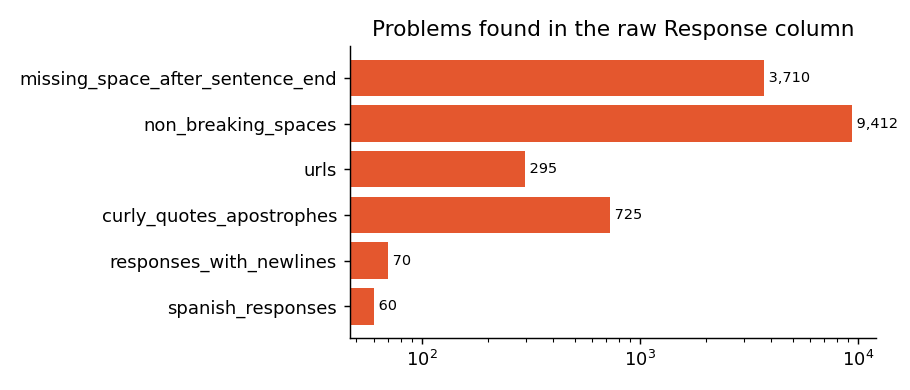

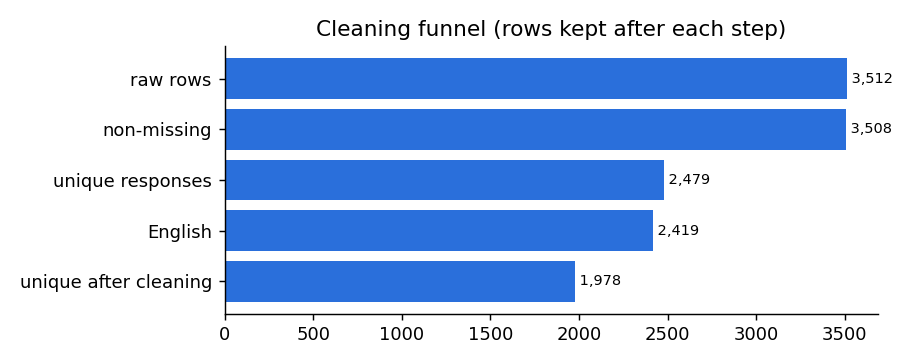

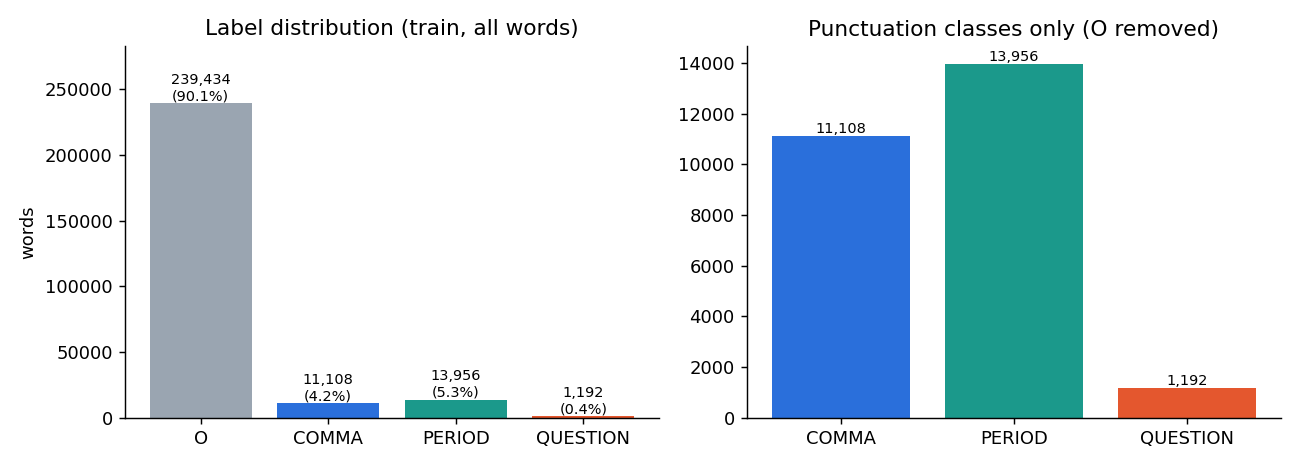

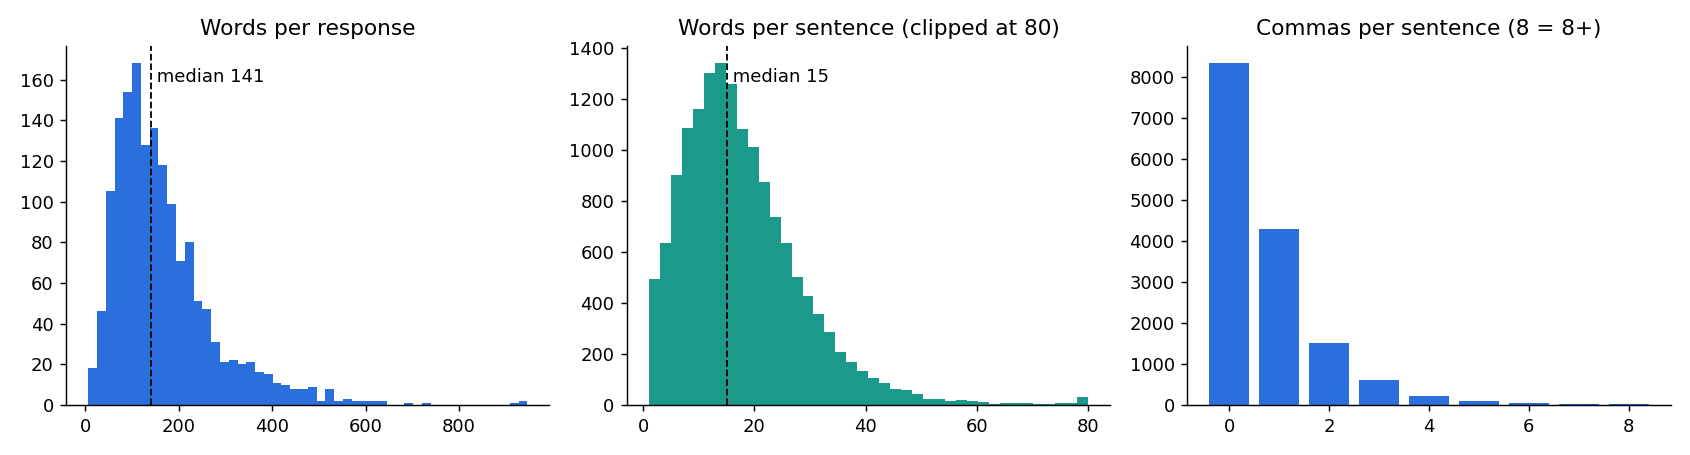

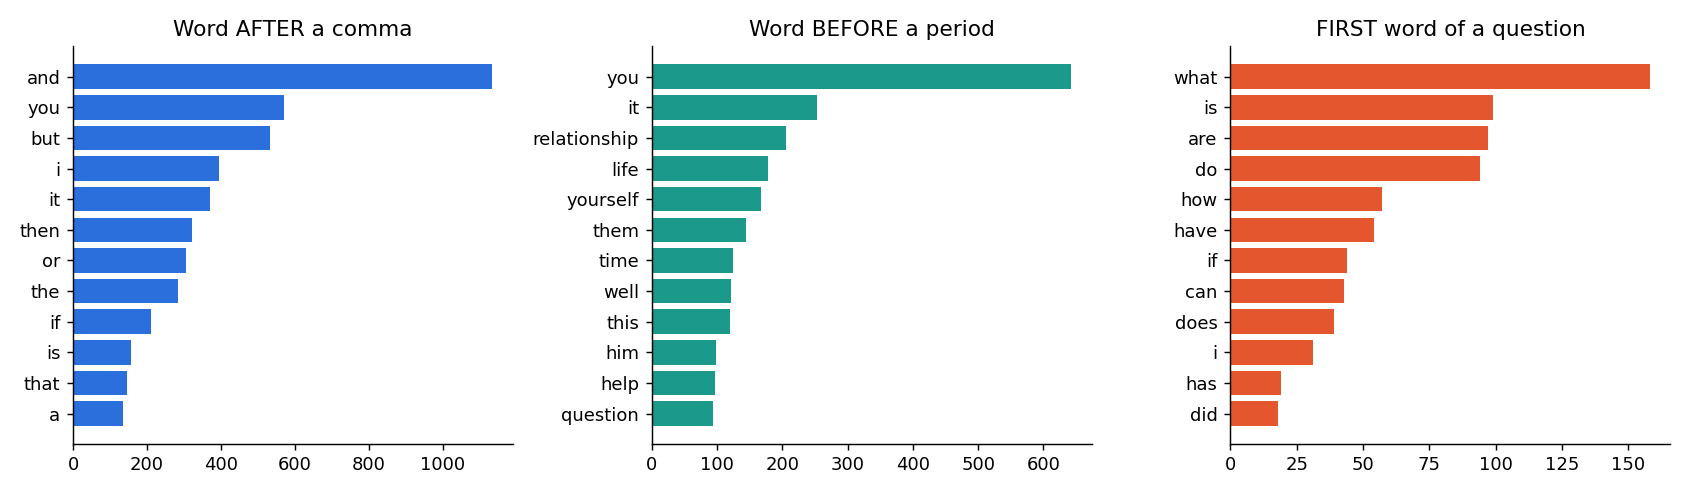

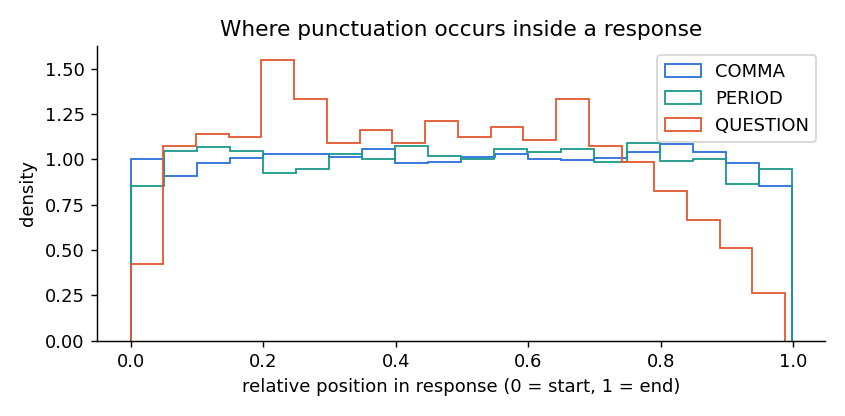

In [18]:
!{sys.executable} scripts/02_eda.py > results/logs/eda.txt
from IPython.display import Image, display
for f in ("eda_raw_issues", "eda_cleaning_funnel", "eda_label_distribution", "eda_lengths", "eda_lexical_cues", "eda_position"):
    display(Image(f"results/figures/{f}.png"))

## 5. Pre-trained end-to-end baselines (zero-shot)

In [19]:
for tag, model in [("punctall_zeroshot", "kredor/punctuate-all"),
                   ("fullstop_zeroshot", "oliverguhr/fullstop-punctuation-multilang-large")]:
    if not os.path.exists(f"results/preds/{tag}.pkl"):
!{sys.executable} scripts/03_run_tagger.py --tag {tag} --model {model}
    print(open(f"results/logs/{tag}.log").read().splitlines()[-3:])

== punctall_zeroshot: kredor/punctuate-all  train=False  device=cuda
tokenizer_config.json: 100% 447/447 [00:00<00:00, 2.21MB/s]
tokenizer.json: 100% 17.1M/17.1M [00:01<00:00, 9.31MB/s]
special_tokens_map.json: 100% 239/239 [00:00<00:00, 1.30MB/s]
config.json: 100% 914/914 [00:00<00:00, 8.54MB/s]
I0000 00:00:1795246178.425208     775 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795246181.772326     775 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
pytorch_model.bin: 100% 1.11G/1.11G [00:05<00:00, 196MB/s]
native labels: {0: '0', 1: '.', 2: ',', 3: '?', 4: '-', 5: ':'}  ->  fold [0, 2, 1, 3, 1, 1]
parameters: 277.5 M
val: micro-F1 0.7423  COMMA 0.625  PERIOD 0.829  QUESTION 0.803  SER 0.423  (5s)
test: micro-F1 0.7536 

## 6. Fine-tuning on the domain (internal LM)

In [20]:
jobs = [("distilbert_finetuned", "distilbert-base-uncased", 3, 5e-5),
        ("punctall_finetuned", "kredor/punctuate-all", 1, 2e-5)]
for tag, model, ep, lr in jobs:
    if not os.path.exists(f"results/preds/{tag}.pkl"):
!{sys.executable} scripts/03_run_tagger.py --tag {tag} --model {model} --train --epochs {ep} --lr {lr}
    print(tag, open(f"results/logs/{tag}.log").read().splitlines()[-3:])

== distilbert_finetuned: distilbert-base-uncased  train=True  device=cuda
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 289kB/s]
config.json: 100% 483/483 [00:00<00:00, 2.31MB/s]
vocab.txt: 232kB [00:00, 764kB/s]
tokenizer.json: 466kB [00:00, 1.78MB/s]
I0000 00:00:1795246295.950385    1411 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795246300.998758    1411 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
model.safetensors: 100% 268M/268M [00:02<00:00, 95.4MB/s]
Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be 

## 7. External LM: GPT-2 N-best rescoring

In [21]:
for tagger in ("distilbert_finetuned", "punctall_finetuned"):
    if os.path.exists(f"results/preds/{tagger}.pkl") and not os.path.exists(f"results/preds/{tagger}+lm_domain.pkl"):
!{sys.executable} scripts/04_external_lm.py --tagger {tagger}
    if os.path.exists(f"results/logs/external_lm_{tagger}.log"):
        print("\n".join(open(f"results/logs/external_lm_{tagger}.log").read().splitlines()[-8:]))

tokenizer_config.json: 100% 26.0/26.0 [00:00<00:00, 127kB/s]
config.json: 100% 762/762 [00:00<00:00, 4.67MB/s]
vocab.json: 1.04MB [00:00, 16.4MB/s]
merges.txt: 456kB [00:00, 910kB/s]
tokenizer.json: 1.36MB [00:00, 1.92MB/s]
I0000 00:00:1795246825.452448    3619 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795246829.021739    3619 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
model.safetensors: 100% 353M/353M [00:02<00:00, 131MB/s]
generation_config.json: 100% 124/124 [00:00<00:00, 653kB/s]
Token indices sequence length is longer than the specified maximum sequence length for this model (302489 > 1024). Running this sequence through the model will result in indexing errors
  LM step 50/592 loss 3.817
  LM step 100/592 

## 8. Evaluation on the held-out test set

In [22]:
!{sys.executable} scripts/05_evaluate_report.py > results/logs/evaluate.txt
t = pd.read_csv("results/tables/test_results.csv")
cols = ["model", "COMMA_F1", "PERIOD_F1", "QUESTION_F1", "micro_P", "micro_R", "micro_F1", "macro_F1", "SER"]
display((t[cols].set_index("model") * 100).round(1))
print(json.dumps(json.load(open("results/tables/significance.json"))["paired"], indent=1))

,COMMA_F1,PERIOD_F1,QUESTION_F1,micro_P,micro_R,micro_F1,macro_F1,SER
model,,,,,,,,
Rule: period at end only,0.0,19.4,0.0,97.0,5.7,10.8,6.5,94.3
XLM-R base punct. model (zero-shot),62.3,85.4,83.7,74.1,76.6,75.4,77.1,40.5
XLM-R large FullStop (zero-shot),64.8,86.8,87.7,76.5,78.3,77.4,79.8,36.4
XLM-R base punct. model + domain FT,67.1,87.6,84.6,80.6,77.7,79.2,79.8,32.7
DistilBERT + domain FT,56.1,78.6,68.4,71.3,67.1,69.1,67.7,47.1
DistilBERT FT + GPT-2 rescoring (generic),61.1,82.3,71.8,75.5,71.2,73.3,71.7,40.7
DistilBERT FT + GPT-2 rescoring (domain),62.0,83.1,75.1,76.0,72.5,74.2,73.4,39.7
XLM-R base FT + GPT-2 rescoring (generic),68.4,87.9,84.7,79.3,79.9,79.6,80.3,32.5
XLM-R base FT + GPT-2 rescoring (domain),69.7,88.7,86.1,80.5,80.8,80.7,81.5,30.9


[
 {
  "A": "punctall_finetuned",
  "B": "punctall_zeroshot",
  "mean_diff": 0.038039796291411195,
  "ci95": [
   0.027686480041469456,
   0.04699317143902032
  ],
  "p_A_not_better": 0.0
 },
 {
  "A": "distilbert_finetuned",
  "B": "punctall_zeroshot",
  "mean_diff": -0.062441337369215075,
  "ci95": [
   -0.08046657404734736,
   -0.04549514908587504
  ],
  "p_A_not_better": 1.0
 },
 {
  "A": "distilbert_finetuned",
  "B": "fullstop_zeroshot",
  "mean_diff": -0.08271608425223227,
  "ci95": [
   -0.0989634091112721,
   -0.0670163975417024
  ],
  "p_A_not_better": 1.0
 },
 {
  "A": "punctall_finetuned",
  "B": "fullstop_zeroshot",
  "mean_diff": 0.017765049408394004,
  "ci95": [
   0.00620015841135288,
   0.029255358360759313
  ],
  "p_A_not_better": 0.001
 },
 {
  "A": "distilbert_finetuned+lm_domain",
  "B": "distilbert_finetuned",
  "mean_diff": 0.05068270006270102,
  "ci95": [
   0.03901764072879042,
   0.061972411219789254
  ],
  "p_A_not_better": 0.0
 },
 {
  "A": "distilbert_finet

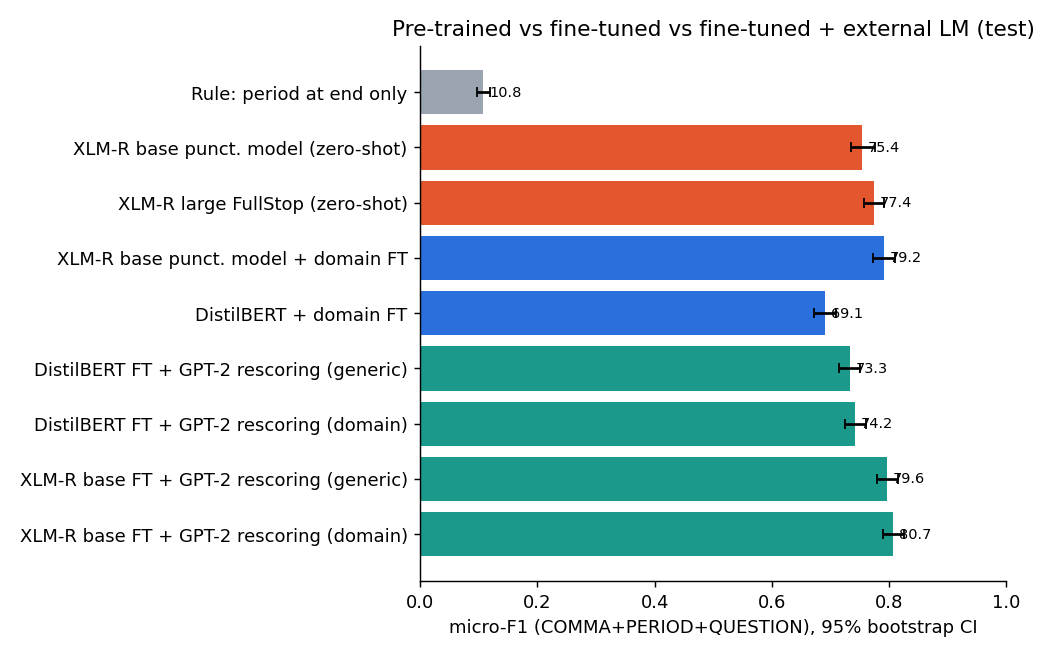

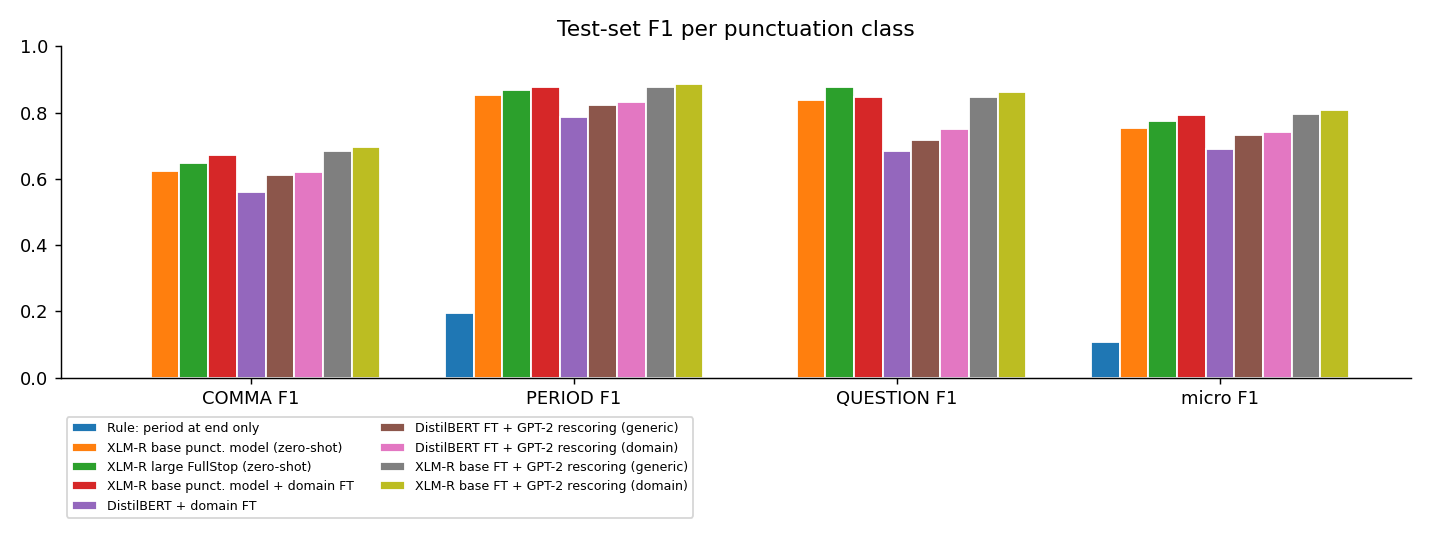

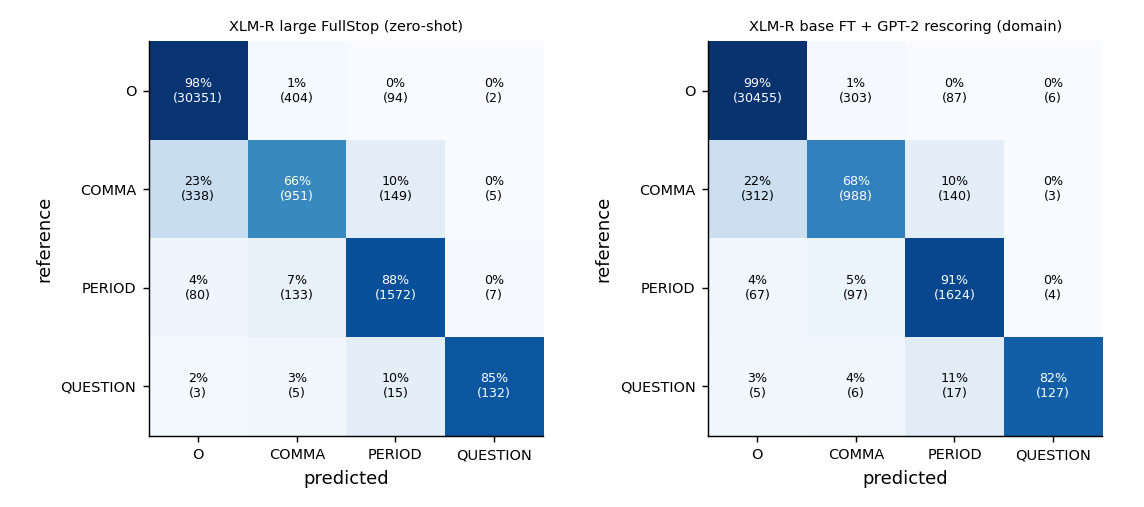

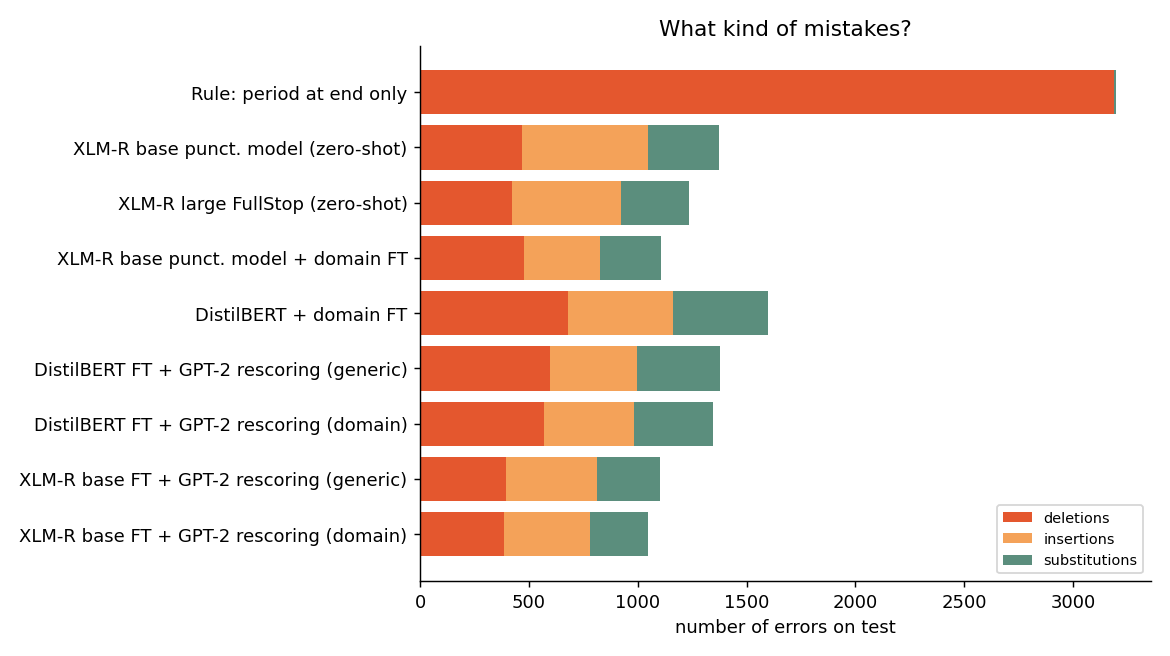

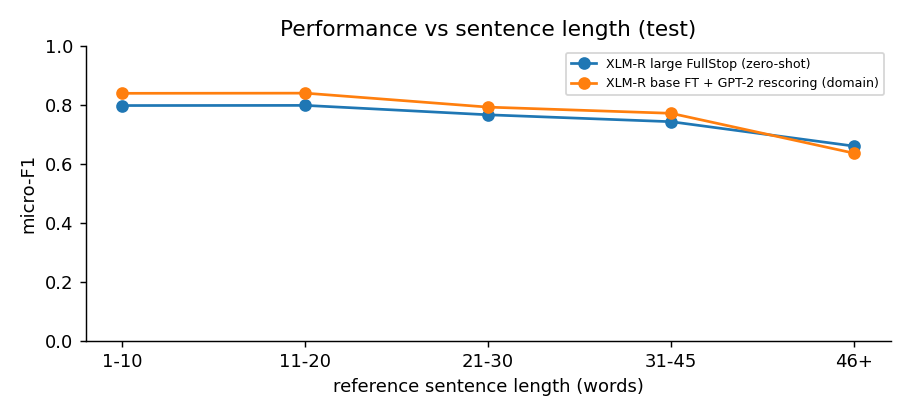

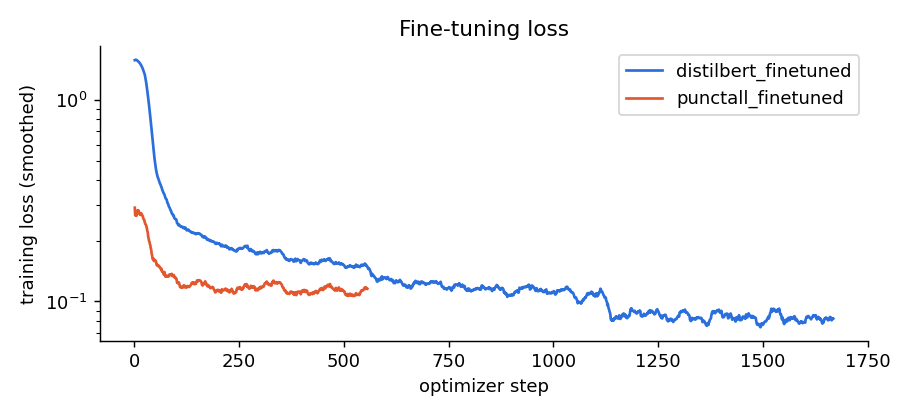

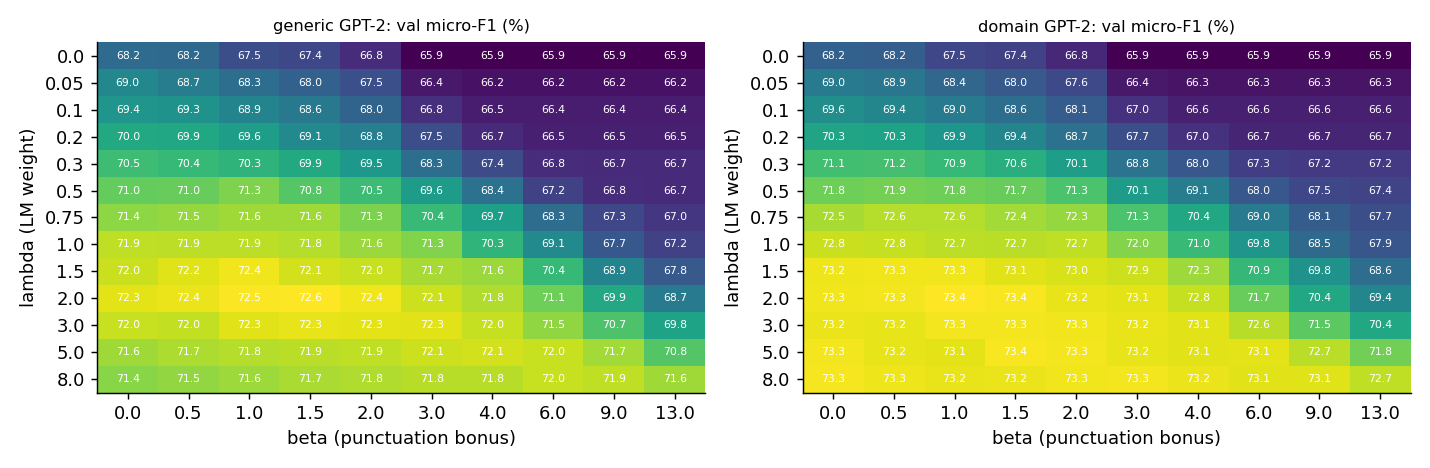

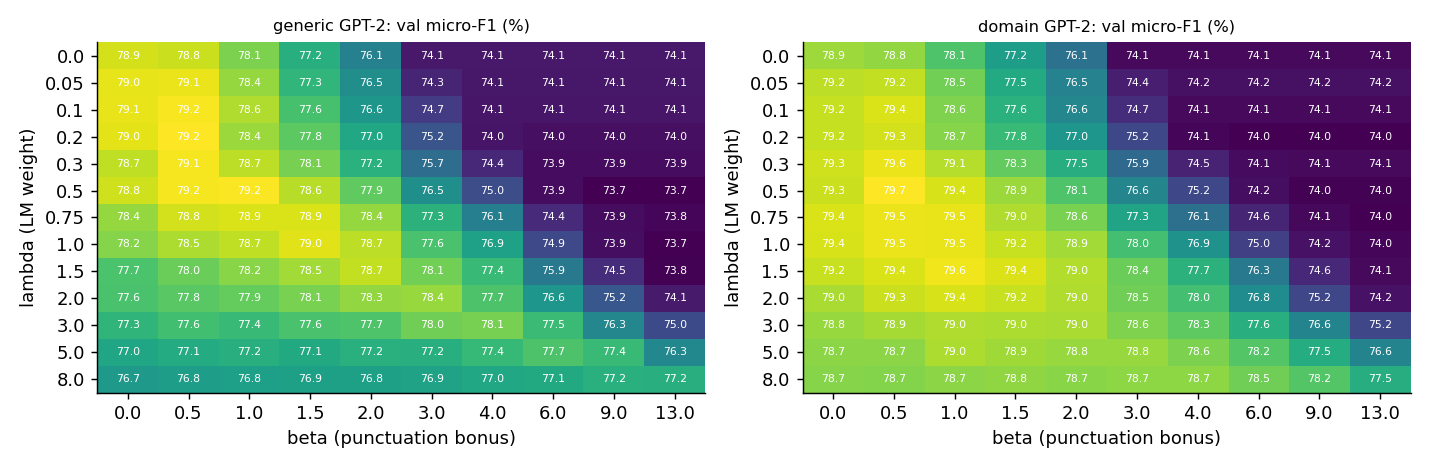

In [23]:
for f in ("res_micro_f1", "res_f1_by_class", "res_confusion", "res_error_types", "res_by_sentence_length",
          "res_training_loss", "res_lm_grid_distilbert_finetuned", "res_lm_grid_punctall_finetuned"):
    if os.path.exists(f"results/figures/{f}.png"):
        display(Image(f"results/figures/{f}.png"))

In [24]:
from IPython.display import Markdown
display(Markdown(open("results/tables/error_examples.md", encoding="utf-8").read()))

# Error analysis examples (test set)

Legend: REF = gold, ZS = fullstop_zeroshot (zero-shot), FT = punctall_finetuned+lm_domain (best fine-tuned system)


### Test response 60

- **INPUT:** yes this emotional abuse there is no abuse without emotional abuse his abuse is demeaning and can have lasting negative impact on your perspective of your self and people around you please find someone support to talk to
- **REF:** Yes, this emotional abuse. There is no abuse without emotional abuse. His abuse is demeaning and can have lasting negative impact on your perspective of your self and people around you. Please find someone support to talk to.
- **ZS:** Yes, this emotional abuse. There is no abuse without emotional abuse. His abuse is demeaning and can have lasting negative impact on your perspective of your self and people around you. Please find someone support to talk to.
- **FT:** Yes, this emotional abuse. There is no abuse without emotional abuse. His abuse is demeaning and can have lasting negative impact on your perspective of your self and people around you. Please find someone support to talk to.

### Test response 190

- **INPUT:** hard to say a whole lot without knowing more however if you focus your attention on her what she's saying what she's feeling instead of trying to make yourself heard and understood first that's often a good step also work on building win win agreements with her and follow through on them those are the areas i see men fall short on most often hope that helps
- **REF:** Hard to say a whole lot without knowing more. However, if you focus your attention on her, what she's saying, what she's feeling instead of trying to make yourself heard and understood first, that's often a good step. Also, work on building win win agreements with her, and follow through on them. Those are the areas I see men fall short on most often. Hope that helps.
- **ZS:** Hard to say a whole lot without knowing more. However, if you focus your attention on her, what she's saying, what she's feeling, instead of trying to make yourself heard and understood first, that's often a good step. Also, work on building win win agreements with her and follow through on them. Those are the areas I see men fall short on most often. Hope that helps.
- **FT:** Hard to say a whole lot without knowing more. However, if you focus your attention on her what she's saying, what she's feeling instead of trying to make yourself heard and understood first, that's often a good step. Also, work on building win win agreements with her and follow through on them. Those are the areas I see men fall short on most often. Hope that helps.

### Test response 155

- **INPUT:** this interaction with your boss seems strange it is tricky to know how to handle workplace conflicts but there are typically resources in place to help employees and mangers communicate successful and feel confident that they are being treated fairly at work is there an hr department that you can use as a mediator
- **REF:** This interaction with your boss seems strange. It is tricky to know how to handle workplace conflicts, but there are typically resources in place to help employees and mangers communicate successful and feel confident that they are being treated fairly at work. Is there an hr department that you can use as a mediator?
- **ZS:** This interaction with your boss seems strange. It is tricky to know how to handle workplace conflicts, but there are typically resources in place to help employees and mangers communicate successful and feel confident that they are being treated fairly at work. Is there an hr department that you can use as a mediator?
- **FT:** This interaction with your boss seems strange. It is tricky to know how to handle workplace conflicts, but there are typically resources in place to help employees and mangers communicate successful and feel confident that they are being treated fairly at work. Is there an hr department that you can use as a mediator?

### Test response 187

- **INPUT:** i would first suggest you sitting down with him and voicing your concerns about how distant he has been or more importantly you have felt that he is this will give clarification to the situation as we need to remember that everyone's perception can be different remember that relationships take work and take communication
- **REF:** I would first suggest you sitting down with him and voicing your concerns about how distant he has been, or more importantly you have felt that he is. This will give clarification to the situation as we need to remember that everyone's perception can be different. Remember that relationships take work and take communication.
- **ZS:** I would first suggest you sitting down with him and voicing your concerns about how distant he has been or, more importantly, you have felt that he is. This will give clarification to the situation, as we need to remember that everyone's perception can be different. Remember that relationships take work and take communication.
- **FT:** I would first suggest you sitting down with him and voicing your concerns about how distant he has been or, more importantly, you have felt that he is. This will give clarification to the situation, as we need to remember that everyone's perception can be different. Remember that relationships take work and take communication.

### Test response 41

- **INPUT:** the greatest sex experience will be with someone who you feel connected to outside the bed this is something that you should feel comfortable in talking with your partner about the relationship needs to be strong before moving to the bed anyways if the love is there he will understand your fears and make you feel comfortable making it a great experience
- **REF:** The greatest sex experience will be with someone who you feel connected to outside the bed. This is something that you should feel comfortable in talking with your partner about. The relationship needs to be strong before moving to the bed anyways. If the love is there, he will understand your fears and make you feel comfortable making it a great experience.
- **ZS:** The greatest sex experience will be with someone who you feel connected to outside the bed. This is something that you should feel comfortable in talking with your partner about. The relationship needs to be strong before moving to the bed. Anyways, if the love is there, he will understand your fears and make you feel comfortable, making it a great experience.
- **FT:** The greatest sex experience will be with someone who you feel connected to outside the bed. This is something that you should feel comfortable in talking with your partner about. The relationship needs to be strong before moving to the bed anyways. If the love is there, he will understand your fears and make you feel comfortable, making it a great experience.

### Test response 17

- **INPUT:** strengthen your own belief in your right to a decent life and respect of who you are from the brief description you write your husband has very limited capacity to recognize how others feel and even less capacity to empathize with the person the best you can do is convince yourself of your own worth and associate with others who believe similarly about your qualities
- **REF:** Strengthen your own belief in your right to a decent life and respect of who you are. From the brief description you write, your husband has very limited capacity to recognize how others feel and even less capacity to empathize with the person. The best you can do is convince yourself of your own worth and associate with others who believe similarly about your qualities.
- **ZS:** Strengthen your own belief in your right to a decent life and respect of who you are. From the brief description you write, your husband has very limited capacity to recognize how others feel and even less capacity to empathize with the person. The best you can do is convince yourself of your own worth and associate with others who believe similarly about your qualities.
- **FT:** Strengthen your own belief in your right to a decent life and respect of who you are. From the brief description you write, your husband has very limited capacity to recognize how others feel, and even less capacity to empathize with the person. The best you can do is convince yourself of your own worth and associate with others who believe similarly about your qualities.

### Test response 115

- **INPUT:** orbetter yet is it you still thinking about the other girl i am sure his cheating hurt you emotionally and may have affected your sexual performance as well make sure the other girl is out the picture on your end as well sounds like something the both of you need to have a calm and adult conversation about
- **REF:** Orbetter yet. Is it you still thinking about the other girl? I am sure his cheating hurt you emotionally and may have affected your sexual performance as well. Make sure the other girl is out the picture on your end as well. Sounds like something the both of you need to have a calm and adult conversation about.
- **ZS:** Orbetter, yet is it you still thinking about the other girl? I am sure his cheating hurt you emotionally and may have affected your sexual performance as well. Make sure the other girl is out the picture on your end as well. Sounds like something the both of you need to have a calm and adult conversation about.
- **FT:** Orbetter yet, is it you still thinking about the other girl? I am sure his cheating hurt you emotionally and may have affected your sexual performance as well. Make sure the other girl is out. The picture on your end as well sounds like something the both of you need to have a calm and adult conversation about.

### Test response 110

- **INPUT:** part of handling stress is making sure that your perception of the stress is accurate sometimes stress can seem more than it really is one thing that i encourage my clients to do is to ask themselves what is this stressor really about simplifying stress is a key to minimizing stress and leads to feeling less stressed out
- **REF:** Part of handling stress is making sure that your perception of the stress is accurate. Sometimes stress can seem more than it really is. One thing that I encourage my clients to do is to ask themselves, what is this stressor really about? Simplifying stress is a key to minimizing stress and leads to feeling less stressed out.
- **ZS:** Part of handling stress is making sure that your perception of the stress is accurate. Sometimes, stress can seem more than it really is. One thing that I encourage my clients to do is to ask themselves, what is this stressor really about? Simplifying stress is a key to minimizing stress and leads to feeling less stressed out.
- **FT:** Part of handling stress is making sure that your perception of the stress is accurate. Sometimes stress can seem more than it really is. One thing that I encourage my clients to do is to ask themselves, what is this stressor really about? Simplifying stress is a key to minimizing stress and leads to feeling less stressed out.

## 9. Try it

In [25]:
from punct.tagger import Tagger
from punct.lm_rescore import ExternalLM
sys.path.insert(0, "scripts"); from predict import punctuate
tagger = Tagger("models/punctall_finetuned")
lm = ExternalLM("models/distilgpt2_domain")
cfg = json.load(open("results/tables/external_lm_punctall_finetuned.json"))["grid"]["domain"]["best"]
for s in ["i understand how hard this must be for you have you talked to anyone about it",
          "it sounds like you are feeling overwhelmed and that is okay many people feel this way after a loss",
          "what would it look like if you allowed yourself to rest without guilt"]:
    print("IN :", s)
    print("OUT:", punctuate(s, tagger))
    print("LM :", punctuate(s, tagger, lm, cfg["lambda"], cfg["beta"]), "\n")

IN : i understand how hard this must be for you have you talked to anyone about it
OUT: I understand how hard this must be for you. Have you talked to anyone about it?
LM : I understand how hard this must be for you. Have you talked to anyone about it? 

IN : it sounds like you are feeling overwhelmed and that is okay many people feel this way after a loss
OUT: It sounds like you are feeling overwhelmed, and that is okay. Many people feel this way after a loss.
LM : It sounds like you are feeling overwhelmed, and that is okay. Many people feel this way after a loss. 

IN : what would it look like if you allowed yourself to rest without guilt
OUT: What would it look like if you allowed yourself to rest without guilt?
LM : What would it look like if you allowed yourself to rest without guilt? 



## 10. Findings, challenges and conclusions